# From agent memory traces to weights: fine-tuning an LLM with LoRA

**A guided notebook on continual learning in weight space**

A support agent at a fictional insurer has spent weeks learning things the official knowledge base never covered: internal abbreviations, error codes, approval limits. This notebook takes that knowledge, moves it into the weights of **Qwen3.5-27B** with LoRA, and measures whether it arrived.

On the first run (9 November 2026, one A100 80GB) the model went from **13% to 82%** on 61 held-out questions after 7 minutes of training, with 0.32% of its parameters trained.

## What you will learn

- What continual learning is, and the difference between learning in **token space** and in **weight space**
- How an agent's **memory traces** become a fine-tuning dataset, and why that dataset is designed and not collected
- What a weight is, what a transformer block does, and how **LoRA** trains a small correction beside frozen weights
- What every parameter in the loading, LoRA and training cells means, before you run the cell that sets it
- How to **evaluate** a fine-tune so the result means something: a held-out set, a baseline, and one change at a time
- What **catastrophic forgetting** is, how to check for it, and how one run becomes a **continual learning loop**

## How the notebook is organised

| Part | What it covers | Runs code? |
|---|---|---|
| 1 | Continual learning in weight space: the big picture | No |
| 2 | The use case: Calderwood Insurance | No |
| 3 | Setup: install the libraries and upload the data | Yes |
| 4 | From traces to training rows | Yes |
| 5 | The model and the hardware | Yes |
| 6 | LoRA, from a single weight to eight target modules | Yes |
| 7 | Chat templates and data formatting | Yes |
| 8 | Evaluation, before anything is trained | Yes (about 10 minutes) |
| 9 | Training | Yes (about 7 minutes) |
| 10 | Measure what changed | Yes (about 10 minutes) |
| 11 | Use it and ship it | Yes |
| 12 | From one run to continual learning | No |
| Reference | Common errors, glossary, further reading | No |

Every part opens with the idea, then explains each parameter **before** the cell that uses it. Where you see **Predict first**, work out the answer before you run the next cell; the cell then checks you.

## What you need

- **An A100 80GB runtime** (Colab Pro: Runtime → Change runtime type → A100, High-RAM). The model is about 54GB in 16-bit. Colab's A100 option can hand you a 40GB card instead, and an L4 has about 22GB; Part 5 checks which one you got and tells you which loading setting to change so the model still fits.
- **`calderwood_data.zip`**, uploaded to the Colab root folder in Part 3.
- **About 45 minutes** end to end: a few minutes to download the weights, about 10 minutes for each of the two scoring passes, and about 7 minutes of training.

The fine-tuning code is built on Unsloth's Qwen3.5-27B A100 notebook. The figures come from the slide deck *Continual Learning Beyond the Context Window*.

---
# Part 1: Continual learning in weight space

## Two words first

**Continual** describes a process that repeats over a period of time, with pauses in between. It is different from *continuous*, which means without stopping.

**Learning** is accumulating information and experience so that future attempts go better.

Put together: **continual learning is accumulating information and experience repeatedly, over time, so that each round does better than the last and keeps what came before.** The last clause matters as much as the first. A system that learns something new and loses something old has not accumulated anything.

## Where can an agent keep a lesson?

A deployed language model is frozen. Its weights are the same on the thousandth request as on the first, which is why an agent built on one learns nothing by default. For the agent to improve, the lesson has to be kept somewhere, and there are three places:

- **Token space** is text outside the model: the database, the files, and the context window assembled from them on each call. The model reads it.
- **Latent space** is the model's working state for one generation: the keys and values it computes from the context and holds in the KV cache. It lasts while the cache is warm.
- **Weight space** is the model itself: its parameters, and any adapters trained on top of them.

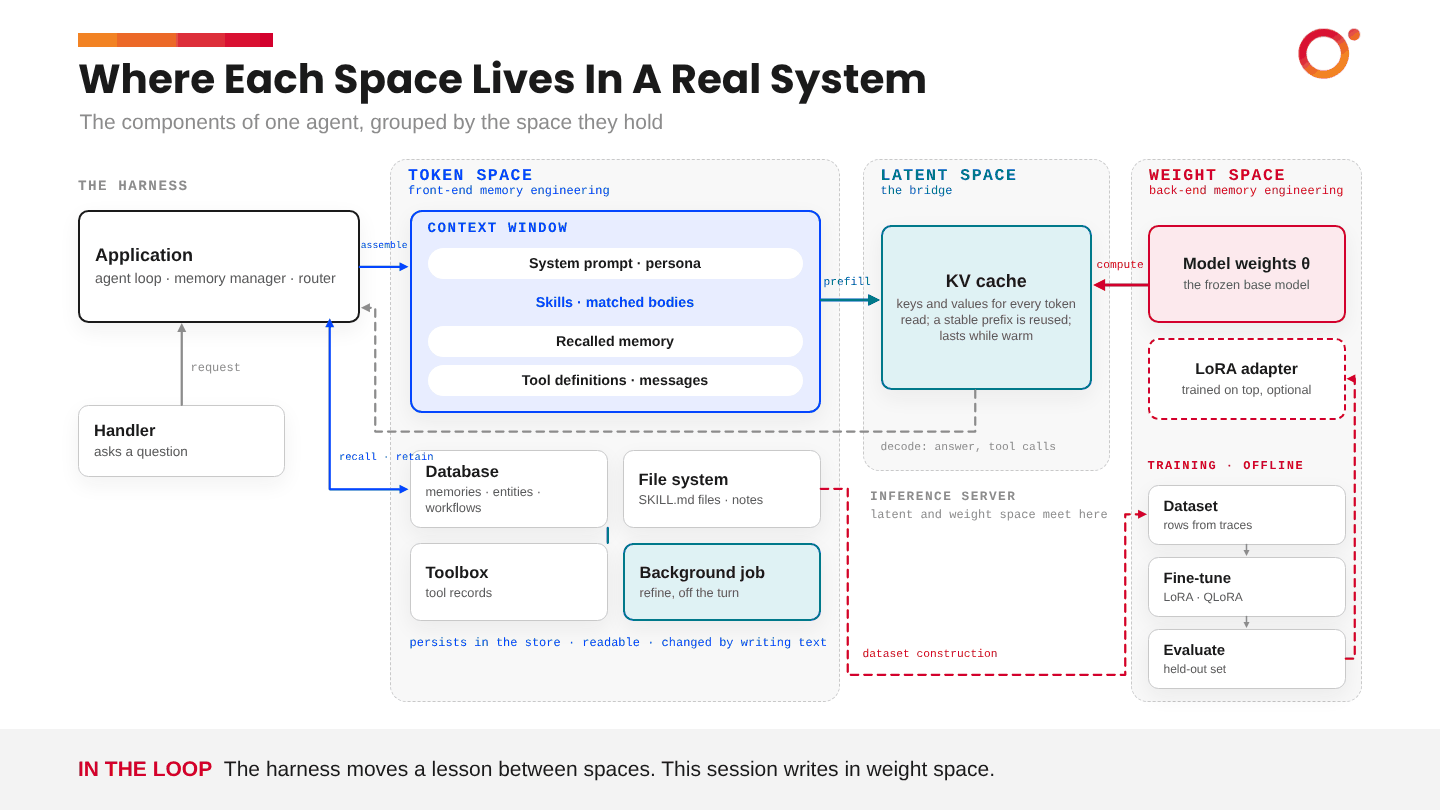

*Figure 1. The three spaces on one running agent. This notebook follows the dashed red route on the right: traces kept in token space become a dataset, a fine-tune and an adapter in weight space.*

The two spaces that persist behave very differently:

| | Token space | Weight space |
|---|---|---|
| What changes | The text the model reads | The parameters themselves |
| How it changes | Write, rewrite or retire a record | A training run, then an evaluation |
| How fast | Instant | Minutes to hours |
| Can you read the lesson? | Yes, it is text | No, you can only test for it |
| Can you undo one lesson? | Yes, edit or remove the record | No clean delete; you train over it |
| Cost at answer time | A search, and a longer prompt | Nothing extra |
| When search misses | The answer is wrong or missing | The model still answers |

This notebook is about the right-hand column. A companion session covers the left.

## Agent memory is the foundation

Nothing in this notebook starts with a dataset someone wrote by hand. It starts with what the agent kept: the traces of its sessions and the memory it wrote during them. **Agent memory is the foundation for continual learning**, because an agent can only improve on what it keeps.

Memory engineering therefore has two ends. **Front-end memory engineering** builds the store: capturing traces, extracting memory, recalling it well. **Back-end memory engineering** decides what crosses from the store into the model, and trains it there. Moving selected memory out of an external store and into the weights is called **consolidation**.

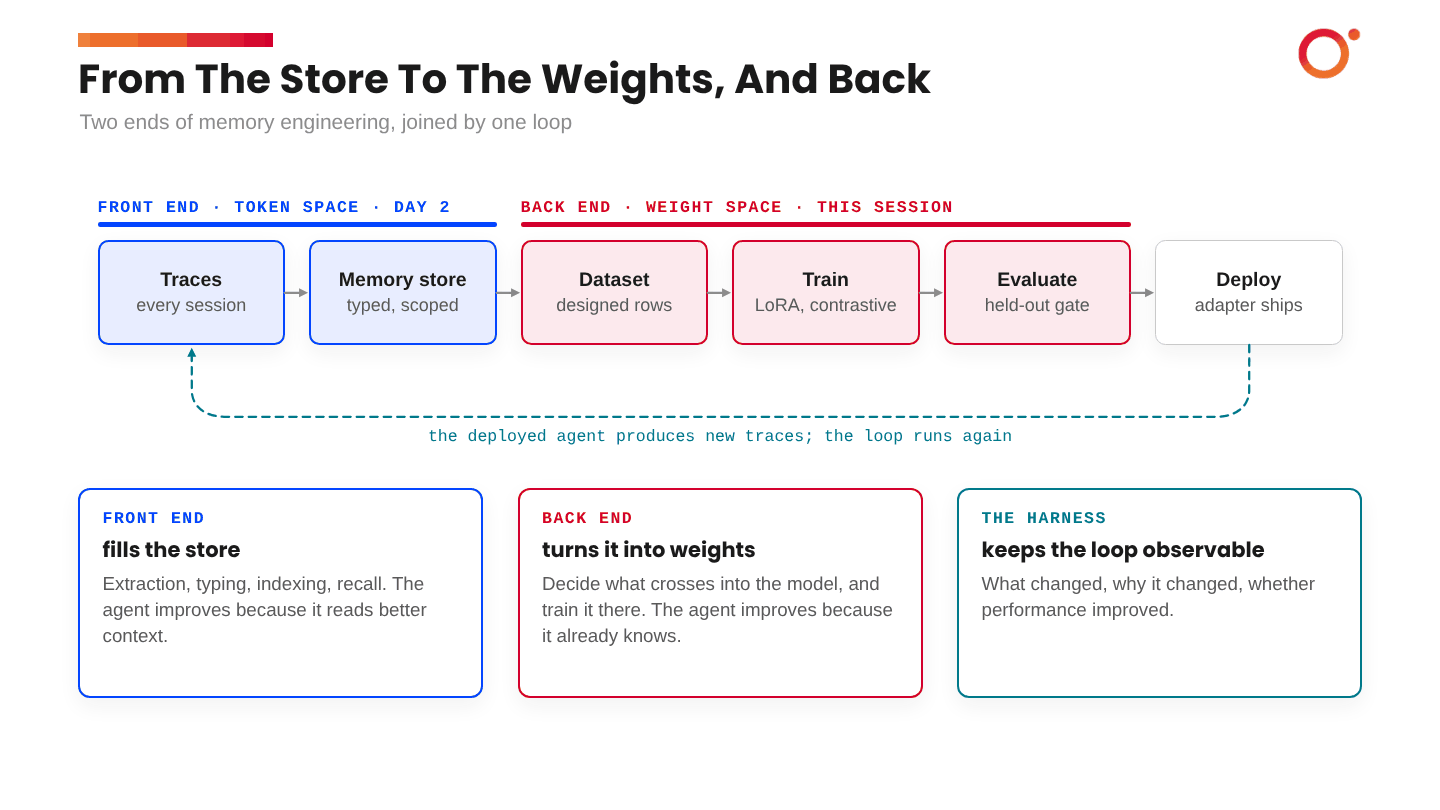

*Figure 2. The two ends of memory engineering. The front end fills the store; the back end turns the stable part of it into weights; the deployed agent produces new traces and the loop runs again.*

## The brain solved this first

The design has a precedent. The theory of **complementary learning systems** says the brain uses two stores. The hippocampus learns an episode in one exposure, fast and specific. The neocortex learns slowly and holds what generalises. During sleep, the hippocampus replays recent experience and the cortex gradually absorbs it.

An agent with memory has the same shape. The memory store is the fast system. The model's weights are the slow one. Consolidation is the replay between them.

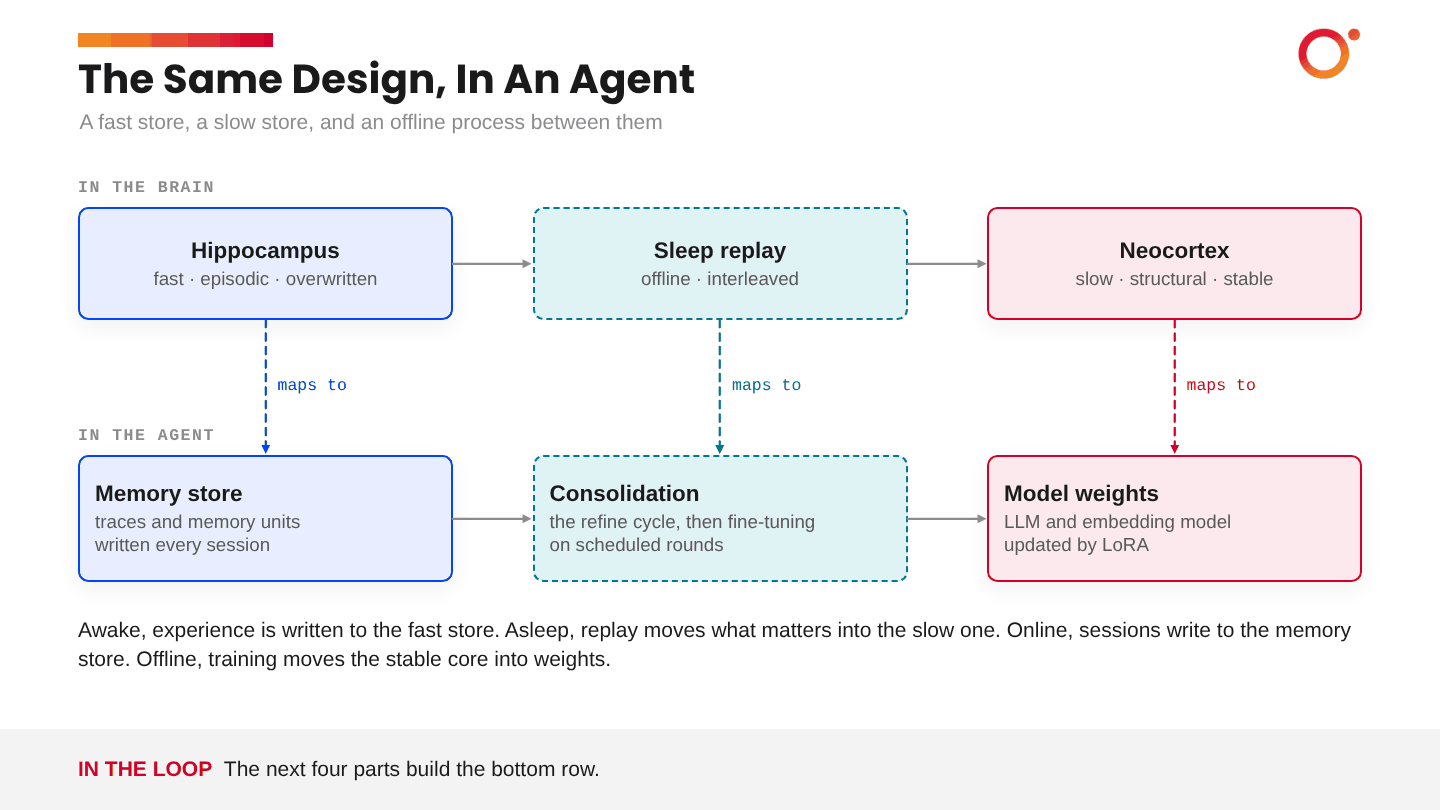

*Figure 3. A fast store, a slow store, and an offline process between them. The bottom row is what this notebook builds.*

## Should this knowledge go in the weights at all?

Not everything should. Retrieval and training are good at different things, and real systems use both: weights for the stable core, retrieval for everything that changes or must be traceable.

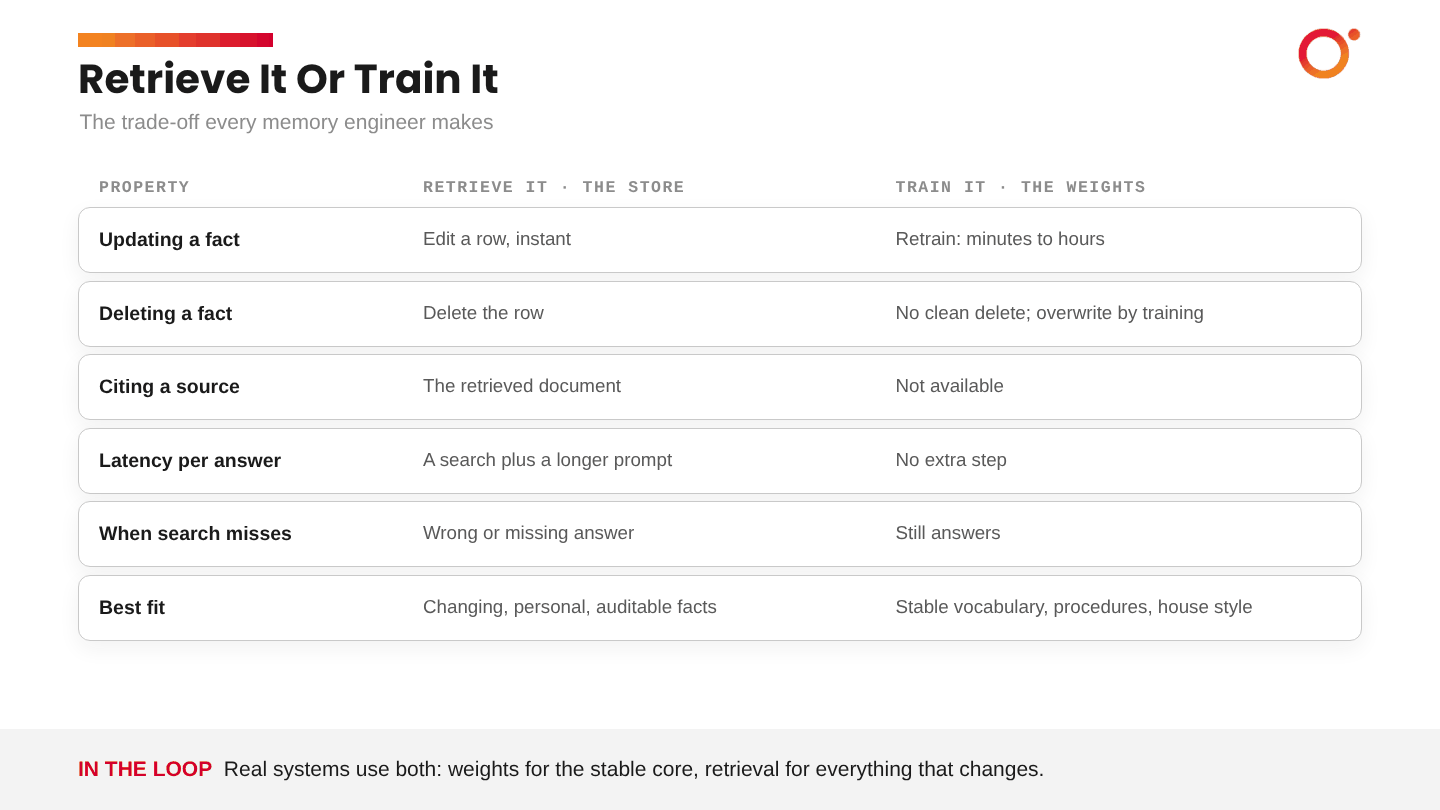

*Figure 4. The same decision as a table. Stable vocabulary and procedures suit weights. Facts that change, belong to one person, or need a source suit the store.*

## What this notebook does

It runs **one round** of the loop, in five steps:

1. A support agent's sessions are logged as **traces**.
2. An extraction step pulls **memory units** out of the traces.
3. Each memory unit becomes several **training rows**.
4. Qwen3.5-27B is **fine-tuned** on those rows with LoRA.
5. The same held-out questions are asked **before and after** training, and the answers are scored.

Steps 1 to 3 have already been done for you and saved as files; Part 4 walks through them. Steps 4 and 5 are Parts 5 to 10. Part 12 shows how this single round becomes a loop that runs every time new traces arrive.

---
# Part 2: The use case, Calderwood Insurance

Calderwood Insurance is a fictional UK insurer. Its internal support assistant answers claims handlers' questions about systems, codes, teams and approval rules. The knowledge it needs is the kind that lives in senior people's heads and not in the official knowledge base. That is exactly the knowledge an agent accumulates as memory, and exactly the knowledge a base model cannot have.

Every name is invented. That is deliberate: because Calderwood does not exist, the base model should score close to zero on its internal knowledge, so **any gain after training can only have come from training**.

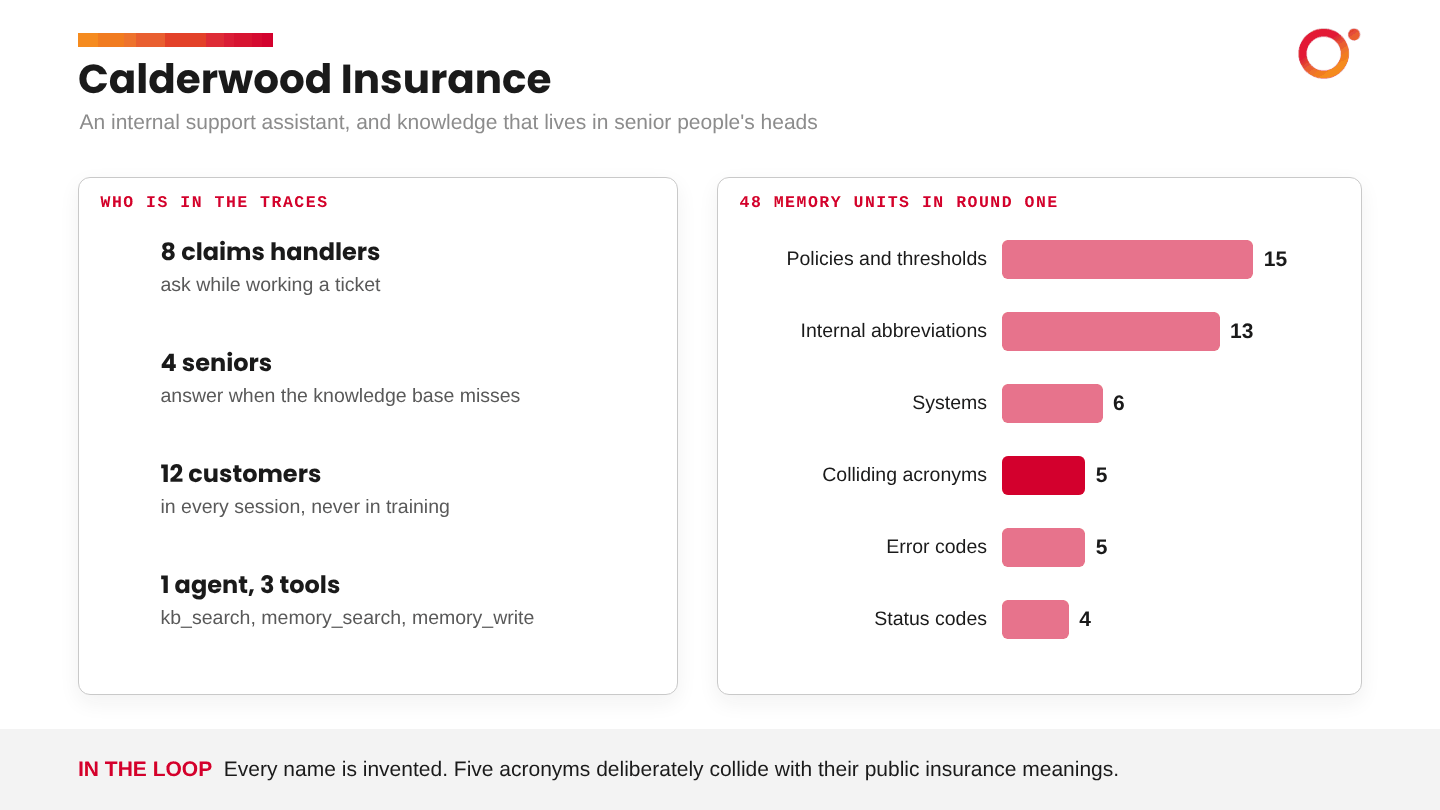

*Figure 5. Who appears in the traces, and what the agent has to learn. Customers and ticket numbers appear in every session and never reach training.*

## What the agent has to learn

| Category | Units | Examples |
|---|---|---|
| Internal abbreviations | 13 | RVF (Rapid Vulnerability Flag), HSR (Hold for Surveyor Review), LLU (Large Loss Unit), Amber Pack (the fraud referral pack) |
| Colliding acronyms | 5 | TPA means Total Payout Authority here, not Third Party Administrator |
| Systems | 6 | Beacon (claims), Atlas (policies), Tally (payments), the Ringfence (sanctions screening), Keystone (legacy), Drop (uploads) |
| Error codes | 5 | BCN-217 attachment over 25MB; ATL-031 policy not found; TLY-409 duplicate payment block; RFN-110 sanctions match |
| Status codes | 4 | Q3 awaiting documents; Q7 awaiting surveyor; Q9 with the Counter Fraud Unit (internal only); Q12 payment released |
| Policies and thresholds | 15 | Payout authority by grade, the goodwill ladder, FNOL within 4 working hours |

## The five acronyms that collide

Five Calderwood acronyms already mean something else in the insurance industry, and the base model has strong associations for every one of them. They are the hardest and most interesting test in the notebook: to pass, the model has to override a meaning it learned in pretraining, but only in the Calderwood context.

| Acronym | Industry meaning | Calderwood meaning |
|---|---|---|
| TPA | Third Party Administrator | Total Payout Authority |
| LAE | Loss Adjustment Expense | Large Account Escalation |
| CAT | Catastrophe | Claims Audit Trail |
| IBNR | Incurred But Not Reported | Internal Broker Notification Request |
| PML | Probable Maximum Loss | Policy Mid-term Lapse |

## The numbers the agent has to keep straight

| Ladder | Level 1 | Level 2 | Level 3 | Above that |
|---|---|---|---|---|
| Payout authority (TPA) | Grade 1: £2,500 | Grade 2: £10,000 | Senior: £50,000 | Large Loss Unit |
| Goodwill approval | Handler: £250 | Desk Lead: £1,000 | Head of Customer Outcomes | |

Keep this table in mind. Similar numbers attached to similar questions interfere with each other, and combining two of them in one answer is harder still. Part 10 shows this is where the first run struggled.

---
# Part 3: Setup

## Install the libraries

The next cell installs the fine-tuning stack. You do not need to change anything in it. What it installs:

| Library | What it does in this notebook |
|---|---|
| **Unsloth** | Loads the model and attaches LoRA, with faster and more memory-efficient training than the plain libraries |
| **Transformers** | The Hugging Face model and tokenizer code underneath Unsloth |
| **PEFT** | The Hugging Face library that implements LoRA |
| **TRL** | Provides `SFTTrainer`, the training loop for supervised fine-tuning |
| **bitsandbytes** | 8-bit optimiser state, and 4-bit model loading if you choose it |
| **torch** | The tensor library everything runs on |

`%%capture` on the first line hides the install output. The cell takes a few minutes. The versions are pinned because this model needs recent releases.

In [ ]:
%%capture
import os, importlib.util
!pip install --upgrade -qqq uv
if importlib.util.find_spec("torch") is None or "COLAB_" in "".join(os.environ.keys()):
    try: import numpy, PIL; _numpy = f"numpy=={numpy.__version__}"; _pil = f"pillow=={PIL.__version__}"
    except: _numpy = "numpy"; _pil = "pillow"
    !uv pip install -qqq \
        "torch==2.8.0" "triton>=3.3.0" {_numpy} {_pil} torchvision "torchaudio==2.8.0" bitsandbytes xformers==0.0.32.post2 \
        "unsloth_zoo[base] @ git+https://github.com/unslothai/unsloth-zoo" \
        "unsloth[base] @ git+https://github.com/unslothai/unsloth"
    !uv pip install -qqq --no-deps "torchcodec==0.7.0"
elif importlib.util.find_spec("unsloth") is None:
    !uv pip install -qqq unsloth
!uv pip install --upgrade --no-deps "tokenizers>=0.22.0,<=0.23.0" trl==0.22.2 unsloth unsloth_zoo
!uv pip install transformers==5.3.0
!unsloth install-kernels
!uv pip install --no-deps --upgrade "torchao>=0.16.0"

## Upload the data

Drag `calderwood_data.zip` onto the **Files** panel on the left, into the root folder (`/content`), then run the cell below. A common mistake is to drop it into `sample_data`; if the cell reports a missing file, that is usually why.

The zip holds four files, one for each stage of the pipeline:

| File | What it holds |
|---|---|
| `traces.jsonl` | The raw agent sessions: messages, tool calls and tool results |
| `memory_units.jsonl` | The memory extracted from those traces |
| `train.jsonl` | Memory units turned into chat-format training rows |
| `eval.jsonl` | Held-out questions with the key terms a correct answer must contain |

In [ ]:
import os, zipfile
if os.path.exists("calderwood_data.zip"):
    zipfile.ZipFile("calderwood_data.zip").extractall(".")
for f in ["traces.jsonl", "memory_units.jsonl", "train.jsonl", "eval.jsonl"]:
    assert os.path.exists(f), f"Missing {f}: upload calderwood_data.zip or the .jsonl files first"
print("All data files found.")

---
# Part 4: From traces to training rows

Fine-tuning data for an agent is **designed, not collected**. This part follows one piece of knowledge through three stages before any GPU is involved.

- A **trace** is the full record of one session: messages, tool calls and tool results, with timestamps.
- A **memory unit** is one self-contained piece of knowledge extracted from traces, with metadata about where it came from.
- A **training row** is a question and an answer built from a memory unit, in chat format.

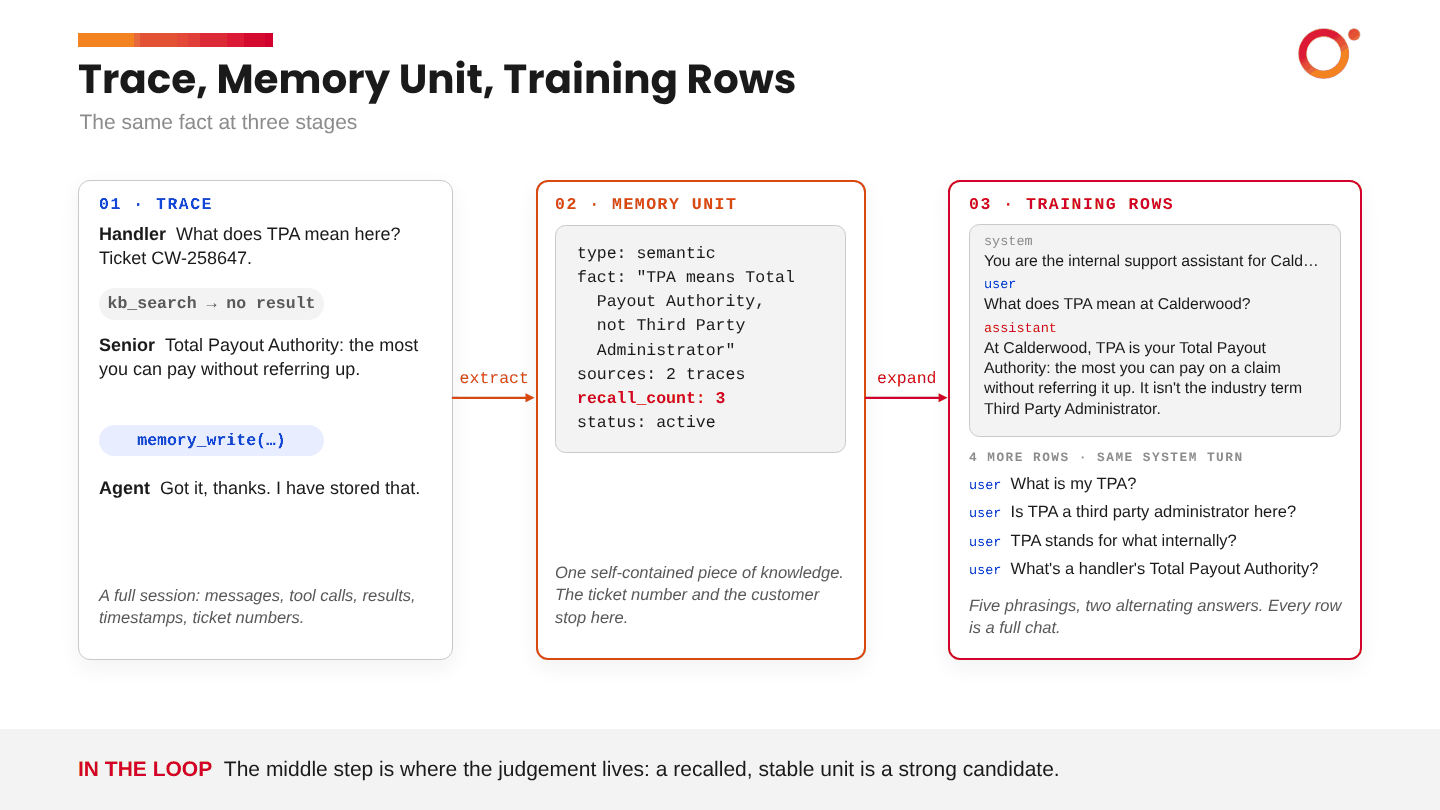

*Figure 6. One fact at three stages. The ticket number and the customer stop at the trace. The memory unit keeps the knowledge. Each training row is a full chat (system, user, assistant), and the fact is asked five ways.*

## How the traces came about

The agent in the traces has three tools: `kb_search` (the official knowledge base, which never covers this knowledge), `memory_search` (its own store) and `memory_write`. The sessions fall into two phases:

- **Teaching sessions.** A handler asks a question, the knowledge base has nothing, a senior handler explains, and the agent writes a memory.
- **Recall sessions.** A few days later a handler asks the same thing in different words, and the agent answers from its memory.

## What a memory unit records

| Field | Meaning |
|---|---|
| `memory_id` | The unit's identifier |
| `memory_type` | `semantic` (a fact or meaning) or `procedural` (how to do something) |
| `content` | The knowledge itself, as one self-contained statement |
| `tags` | The category: abbreviation, collision, system, error code, status code or policy |
| `first_seen` | When the agent first wrote it |
| `source_trace_ids` | The traces it came from |
| `recall_count` | How many later sessions found it with `memory_search` |

`recall_count` is worth a second look. A unit that keeps getting recalled is knowledge the desk uses again and again, which makes it a strong candidate for consolidation into weights.

## Which memory belongs in weights

There are three kinds of memory, and they do not all belong in the model:

- **Semantic** memory is facts and meanings: "TPA means Total Payout Authority."
- **Procedural** memory is how to do things: "For BCN-217, split the file."
- **Episodic** memory is specific events: "On 1 September, Tom asked about ticket CW-258647 for Ms Kowalski."

Semantic and procedural knowledge is stable and reused in many situations, so it repays the cost of training. Episodic memory is specific, often personal, changes constantly, and needs exact recall with a source. Weights are bad at all of that, so episodic detail stays in the store.

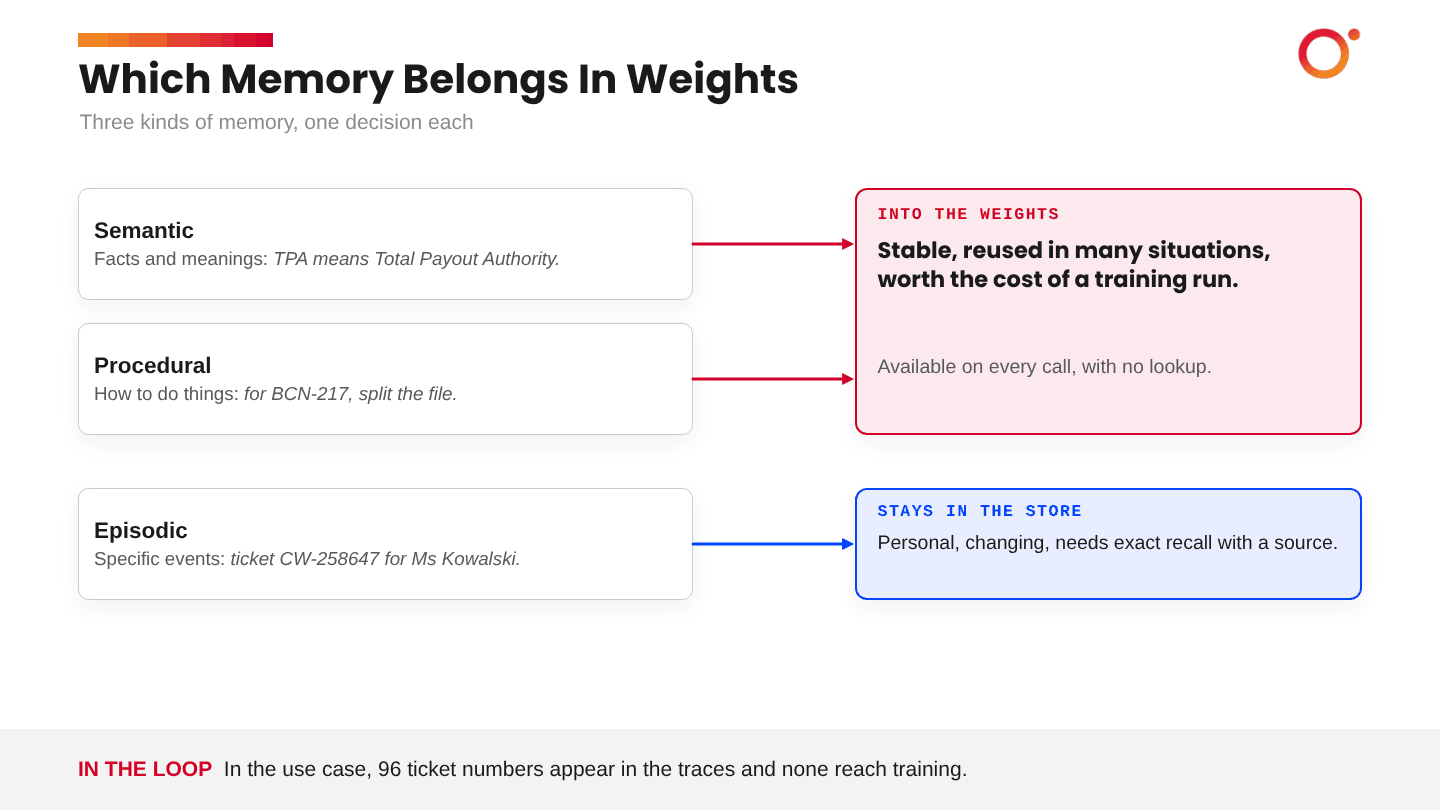

*Figure 7. Three kinds of memory and one decision each. In this dataset 96 ticket numbers appear in the traces and none reach the training rows.*

## Look at the data

The next cell loads the four files and prints one trace, the memory unit extracted from it, and the training rows built from that unit. Read the output in that order.

**What to notice:** the trace is full of ticket numbers, customer names and timestamps. The memory unit has none of them. That gap is the extraction step doing its job.

In [ ]:
import json
from collections import Counter

traces      = [json.loads(l) for l in open("traces.jsonl")]
units       = [json.loads(l) for l in open("memory_units.jsonl")]
train_rows  = [json.loads(l) for l in open("train.jsonl")]
eval_items  = [json.loads(l) for l in open("eval.jsonl")]
print(f"{len(traces)} traces -> {len(units)} memory units -> {len(train_rows)} training rows | {len(eval_items)} held-out eval questions")

print("\n=== 1. RAW TRACE:", traces[0]["trace_id"], "(first 8 events) ===")
for e in traces[0]["events"][:8]:
    if e["type"] == "message":
        print(f'{e["sender"]:>26}: {e["content"]}')
    else:
        payload = e.get("args", e.get("content"))
        print(f'{"":>26}  [{e["type"]}: {e["tool"]}] {json.dumps(payload, ensure_ascii=False)}')

u = units[0]
print("\n=== 2. MEMORY UNIT EXTRACTED ===")
print(json.dumps(u, indent=2, ensure_ascii=False))

print("\n=== 3. TRAINING ROWS BUILT FROM", u["memory_id"], "===")
for r in train_rows:
    if r["memory_id"] == u["memory_id"]:
        print("Q:", r["conversations"][1]["content"])
        print("A:", r["conversations"][2]["content"], "\n")

print("Eval questions by category:", dict(Counter(e["category"] for e in eval_items)))

## Why every fact is asked five ways

This is the most important idea in the data design.

Train on "What does BCN-217 mean?" once, and the model can learn to complete that exact string without learning the fact. Ask "I'm getting BCN-217 when attaching photos, what do I do?" and it may have nothing. Research on how language models store knowledge found that facts became reliably extractable only when training included **many varied rewrites** of them. One phrasing produces recall of that phrasing and little else.

So every memory unit becomes **five questions with two alternating answers**. The variety forces the model to attach the knowledge to the concept and not to a sentence.

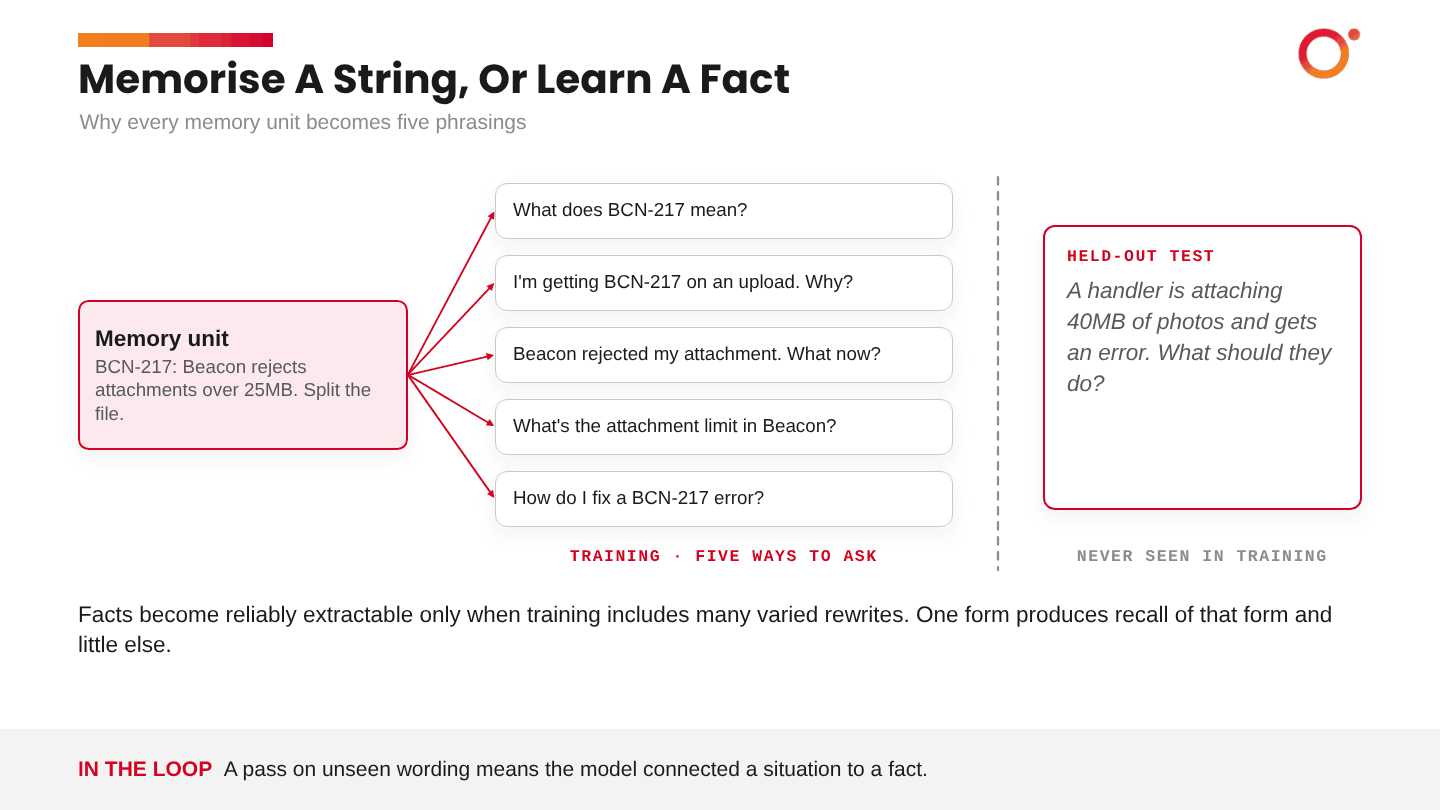

*Figure 8. One memory unit, five training phrasings, and a held-out question the model never sees in training.*

## The held-out test

`eval.jsonl` asks about the same facts in wording that appears in neither the traces nor the training rows. Many of the questions are small scenarios. A pass means the model connected a situation to a fact; testing with the training questions would only measure memorisation.

Each eval item carries **key terms** in `must_include`. It is a list of groups, and an answer passes if **every group** has **at least one** of its alternatives in the answer. Part 8 builds the scorer.

The next cell prints every way one fact is asked in training, then the held-out question for the same fact. Ask yourself: would a model that had only memorised the training strings pass the held-out one?

In [ ]:
fact = "BCN-217"
unit_ids = {u["memory_id"] for u in units if fact in u["content"]}

print(f"TRAINING: every way the {fact} unit is asked in train.jsonl")
for r in train_rows:
    if r.get("memory_id") in unit_ids:
        print("  Q:", r["conversations"][1]["content"])

print(f"\nHELD-OUT: the eval question for the same fact, and the key terms an answer must contain")
for e in eval_items:
    if fact in e["question"] and e["category"] == "error_code":
        print("  Q:", e["question"])
        print("  must_include:", e["must_include"])

The data generator checks four things before it writes any file, so the test cannot leak:

1. No eval question appears in the training rows.
2. No eval question appears in the traces.
3. Every key term an eval question needs is taught somewhere in the training answers.
4. No question passes on its own words, so an answer cannot pass by echoing the question.

---
# Part 5: The model and the hardware

Qwen3.5-27B has about 27 billion parameters. Before loading it, it is worth being able to say how much memory that needs, because every memory setting in the notebook follows from that sum.

## Counting memory

Each parameter is a number, and a number takes a fixed amount of space depending on its **precision**:

| Precision | Bytes per parameter | What it is |
|---|---|---|
| fp32 | 4 | Full 32-bit floating point |
| bf16 | 2 | "Brain float" 16-bit: fp32's range with fewer digits. The standard for training because it rarely overflows |
| 8-bit | 1 | **Quantised**: stored coarsely to save memory, at some cost in accuracy |
| 4-bit | 0.5 | Quantised further. Training LoRA on a 4-bit base is called **QLoRA** |

Training needs more than the weights. Three other piles of numbers have to sit on the same GPU:

| | What it is | How big | Full fine-tuning (27.4B trainable) | LoRA, this run (88.3M trainable) |
|---|---|---|---|---|
| **Gradients** | For each *trainable* number, one more number saying which way to nudge it and how hard | 1 value per trainable parameter | 27.4B × 2 bytes ≈ 55GB | 88.3M × 4 bytes ≈ 0.35GB |
| **Optimiser state** | The Adam optimiser's memory: a running average of each gradient, and of its square | 2 values per trainable parameter | 2 × 27.4B × 4 bytes ≈ 219GB | 2 × 88.3M × 1 byte ≈ 0.18GB (the 8-bit optimiser) |
| **Activations** | The intermediate results of the forward pass, kept so the backward pass can work out the gradients | Grows with batch size × tokens per row, not with trainable parameters | 10GB or more | Roughly 0.65GB |

**A tiny example.** Say the model has one trainable number, $w = 0.50$.

- *Activation.* In the forward pass the input $x = 2.0$ arrives and the layer computes $w \times x = 1.0$. It has to remember $x$, because the gradient of $w$ depends on it.
- *Gradient.* The backward pass reports that raising $w$ raises the loss, say $g = +0.30$.
- *Optimiser state.* Adam does not step by $g$ directly. It keeps a smoothed average of recent gradients (say $m = 0.21$) and of their squares ($v = 0.05$), and steps by $m / \sqrt{v}$. Those two numbers are stored for every trainable weight between steps.

Full fine-tuning would need about 340GB in total, four times what one 80GB card holds. LoRA makes only 0.32% of the model trainable, so the first two piles shrink from 274GB to about half a gigabyte. Activations do not shrink the same way, because the data still flows through the whole frozen model. That is the pile you control with batch size and row length.

The gradient and optimiser figures follow from the parameter counts (assuming 4-byte gradients). The activation figure is what was left over in the first run, which added about 1.1GiB in total, so treat it as a rough estimate.

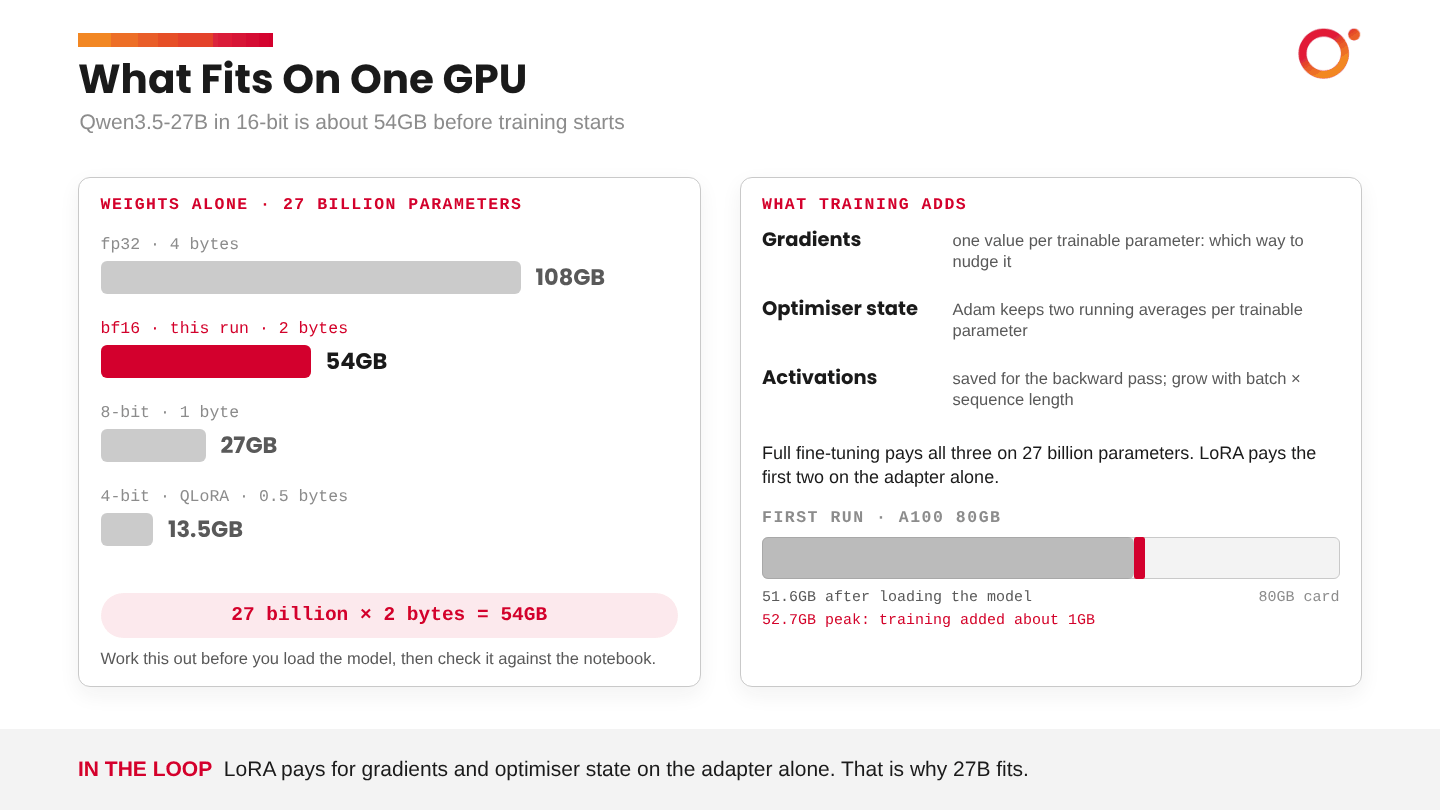

*Figure 9. What fits on one GPU. In the first run the model took 51.6GB once loaded, and training added about 1GB on top.*

**Predict first.** The model has about 27.4 billion parameters and this run loads it in bf16. How many gigabytes is that? Work it out, then run the cell.

In [ ]:
params = 27.4e9   # parameters in Qwen3.5-27B
bytes_per_param = {"fp32": 4, "bf16 (this run)": 2, "8-bit": 1, "4-bit (QLoRA)": 0.5}

for name, size in bytes_per_param.items():
    total = params * size
    print(f"{name:<16} {total / 1e9:6.1f} GB   = {total / 1024**3:6.1f} GiB")

Two columns, because there are two conventions. A **GB** is 1,000³ bytes; a **GiB** is 1,024³ bytes. The memory cells later in this notebook divide by 1,024 three times, so they report GiB even though they print "GB". Expect them to show the bf16 figure from the right-hand column, plus a little overhead for the CUDA context and buffers.

## Which GPU did you get?

The notebook is written for an 80GB card. Colab does not always give you one, so check before downloading 54GB of weights.

In [ ]:
import subprocess

try:
    out = subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader,nounits"],
                         capture_output = True, text = True).stdout.strip().splitlines()[0]
    name, mib = [x.strip() for x in out.split(",")]
    gib = int(mib) / 1024
    print(f"GPU: {name}, {gib:.1f} GiB")
    if gib >= 60:
        print("Enough for the notebook as written: 16-bit weights.")
    elif gib >= 35:
        print("Not enough for 16-bit. In the loading cell set load_in_4bit = True (or load_in_8bit = True).")
    elif gib >= 21:
        print("Set load_in_4bit = True in the loading cell. If training runs out of memory, use batch size 2 with gradient accumulation 4.")
    else:
        print("Too small for this model. Change the runtime type.")
except Exception as e:
    print("No GPU found. Change the runtime type to a GPU before going on.", e)

| Card | Shows as | Loading setting | Weights on the GPU | Notes |
|---|---|---|---|---|
| A100 80GB | about 80 GiB | As written (all three flags `False`) | about 51 GiB | The reference run |
| A100 40GB | about 40 GiB | `load_in_4bit = True`, or `load_in_8bit = True` | roughly 14 to 20 GiB in 4-bit, about 27 GiB in 8-bit | 4-bit is the standard QLoRA route and leaves the most headroom. 8-bit is closer to the reference but slower |
| L4 | about 22.5 GiB | `load_in_4bit = True` | roughly 14 to 20 GiB | Only a few GiB spare for training, so keep rows short and the batch small |

Colab's resource panel shows GiB under the label "GB". A quantised model should score close to the 16-bit reference, but not identically.

## Loading the model: the parameters

`FastLanguageModel.from_pretrained` is Unsloth's entry point. It downloads the weights (about 54GB, a few minutes) and returns the model and its tokenizer.

| Parameter | Value here | What it means |
|---|---|---|
| `model_name` | `"unsloth/Qwen3.5-27B"` | The model to download from the Hugging Face Hub |
| `max_seq_length` | `2048` | The most tokens one training row may hold. Longer rows are cut off, silently losing the end of the answer. The longest Calderwood row is under 200 tokens, so there is plenty of room |
| `load_in_4bit` | `False` | `True` would load the base model in 4-bit (about 13.5GB) and make this a QLoRA run. It fits a much smaller GPU at a modest cost in quality |
| `load_in_8bit` | `False` | `True` would load it in 8-bit (about 27GB) |
| `full_finetuning` | `False` | `False` keeps the base weights frozen so LoRA can be attached. `True` would train every weight, which needs far more memory than one GPU has |

With all three flags `False`, the model loads in plain 16-bit. The A100 has room for it, and an unquantised base gives a cleaner baseline for teaching.

**What Unsloth adds.** The stack underneath is Hugging Face: Transformers for the model, PEFT for LoRA, TRL for the trainer. Unsloth wraps these with faster kernels and memory optimisations. The concepts are identical to the plain libraries.

In [ ]:
from unsloth import FastLanguageModel
import torch

model, tokenizer = FastLanguageModel.from_pretrained(
    model_name = "unsloth/Qwen3.5-27B",
    max_seq_length = 2048, # our rows are short (under 200 tokens)
    load_in_4bit = False,
    load_in_8bit = False,
    full_finetuning = False,
)

Check the prediction. The next cell reports how much GPU memory is reserved now that the model is loaded.

In [ ]:
loaded = torch.cuda.max_memory_reserved() / 1024**3
print(f"{loaded:.1f} GiB reserved after loading the model")

If you loaded in 16-bit, the figure should be close to your prediction. If you loaded a quantised model it will be lower, in line with the table above.

**Only if you loaded in 8-bit.** The 8-bit layers work in float16 while the rest of the model passes bf16 numbers, so every layer logs a line saying it is converting its input: `MatMul8bitLt: inputs will be cast from torch.bfloat16 to float16`. It is harmless, and it prints once per layer per generated token, which floods the output during evaluation. The next cell silences it. It does nothing on a 16-bit or 4-bit load.

In [ ]:
import logging, warnings

logging.getLogger("bitsandbytes.autograd._functions").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", message = ".*MatMul8bitLt.*")

---
# Part 6: LoRA, from a single weight to eight target modules

**LoRA** (Low-Rank Adaptation) freezes the 27 billion base weights and trains a small correction beside each chosen layer. Only the correction is learned, saved and shipped. To see why that works, start with what a weight is.

## 6.1 What a weight is

A layer of a neural network is a grid of numbers, called a **matrix** and written $W$. It takes a list of numbers in, $x$, and gives a list of numbers out, $y$:

$$y = W x$$

Each output number is a weighted sum of the inputs. Every number in $W$ is a **weight**. Training compares the output with the right answer and nudges every weight a little in the direction that would have made the output better.

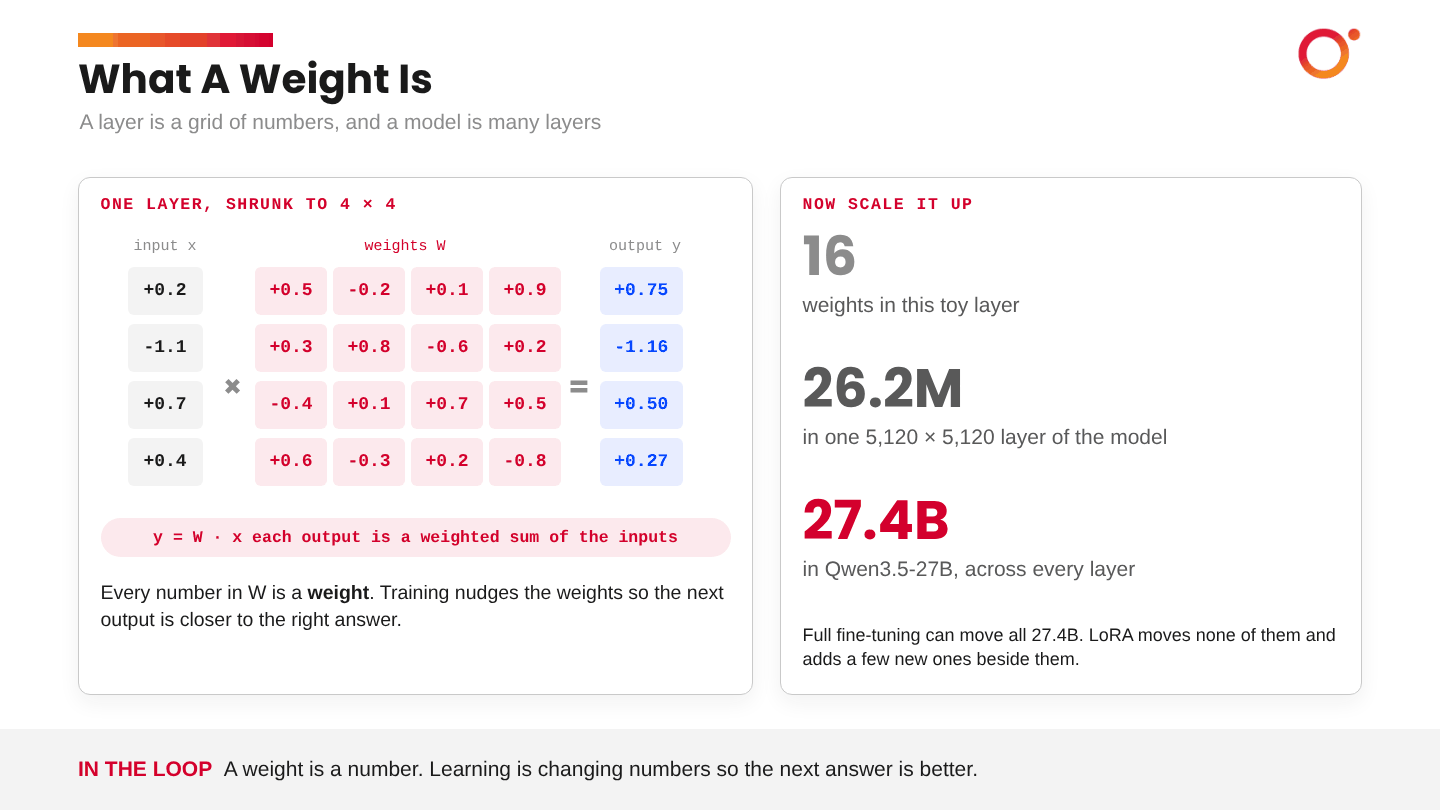

*Figure 10. One layer shrunk to 4 × 4, then scaled up. Full fine-tuning can move all 27.4 billion weights. LoRA moves none of them and adds a few new ones beside them.*

## 6.2 Where the weights live: the transformer block

A language model turns each token into a list of numbers, then passes those numbers through the same kind of **block** again and again. The top of the stack predicts the next token. One block has two halves:

- **Attention** moves information *between* tokens. Each token looks at the others and pulls in what it needs.
- The **MLP** (multi-layer perceptron) works on each token *on its own*. Research suggests much of a model's factual knowledge is stored here.

Each half **adds** its change to what came in (the "+" in the figure, called the residual connection), so a block nudges a token's numbers and does not replace them.

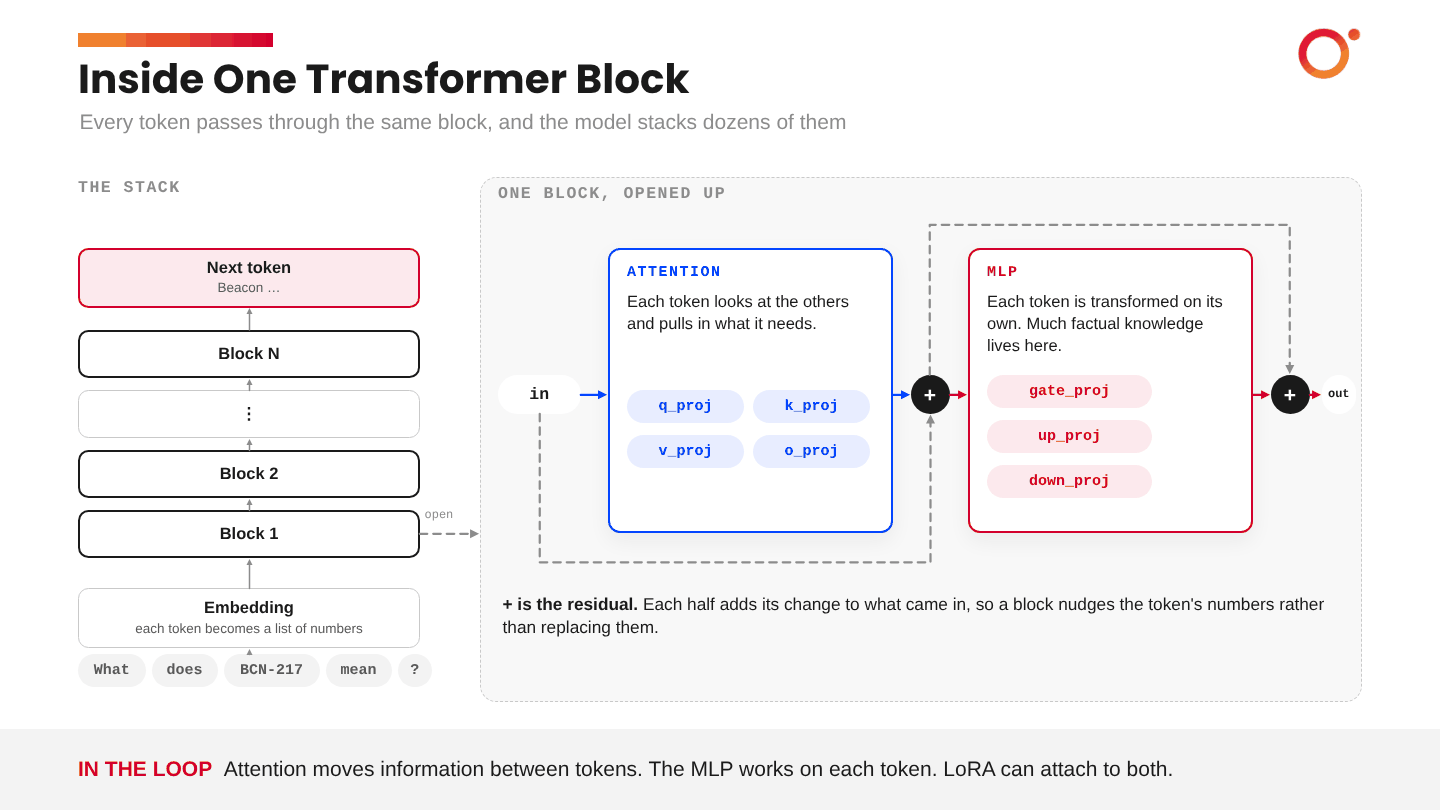

*Figure 11. The stack on the left, one block opened on the right. The names in the chips are the matrices LoRA can attach to.*

## 6.3 How attention works, for one token

Take the question "What does BCN-217 mean?" and follow the last word, *mean*:

1. **Query.** A matrix called `q_proj` turns *mean* into a query: in effect, "what do I refer to?"
2. **Key.** A matrix called `k_proj` turns every token into a key: what it can be found by.
3. **Score.** The query is compared with every key, and a softmax turns the scores into weights that add up to 1. Here most of the weight lands on *BCN-217*.
4. **Value.** A matrix called `v_proj` gives every token a value: what it passes on when it is found.
5. **Output.** *mean* takes in mostly BCN-217's value, and `o_proj` mixes that back into the token's own numbers, which flow on to the MLP.

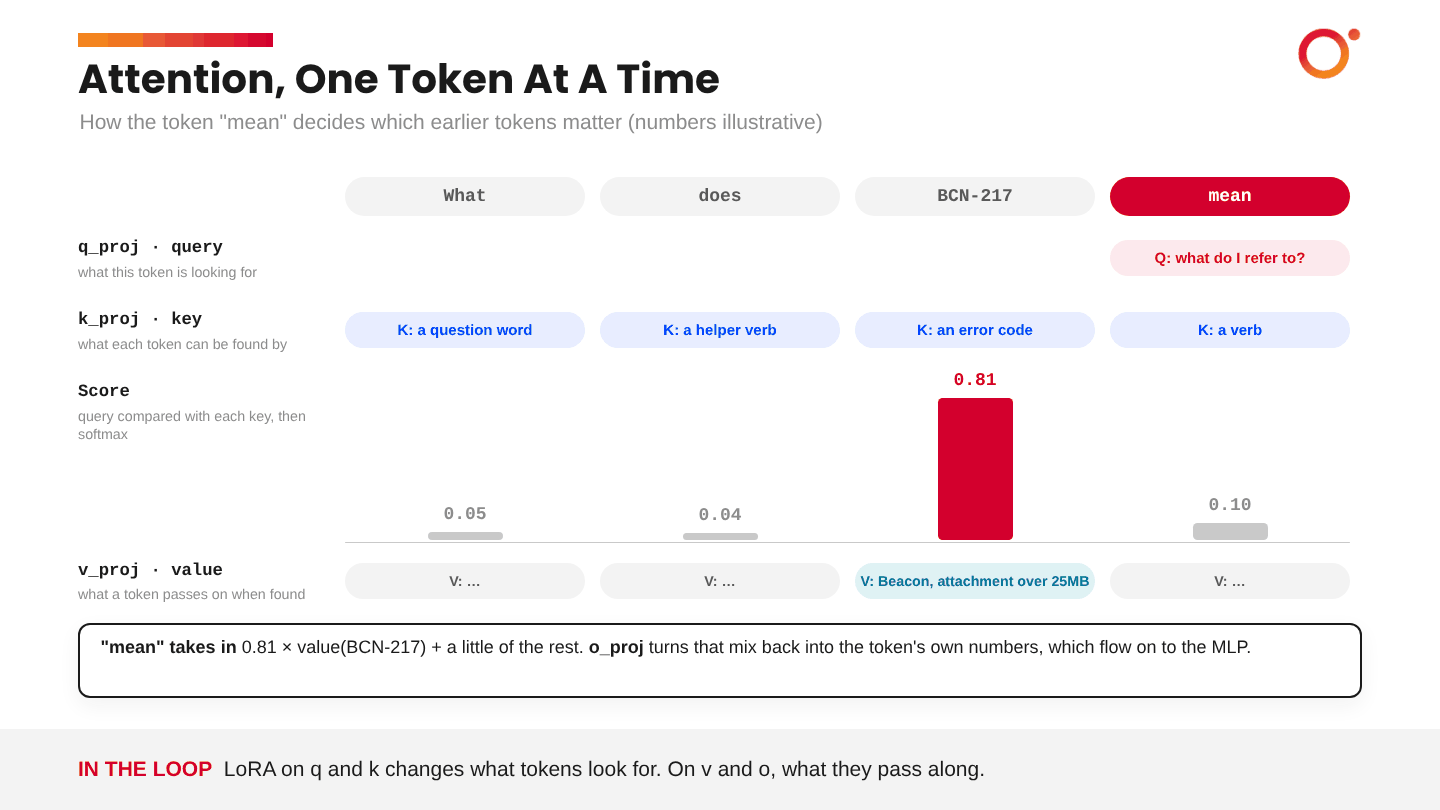

*Figure 12. Attention for the token "mean". The labels and scores are illustrative; the real keys, queries and values are lists of numbers.*

**A library analogy.** You walk in wanting "a book about error codes". That request is your query. Every book has a label on its spine, which is its key. You compare your request with every spine, and the best match is the book you open. What you read inside is its value. The spine and the contents are different things: the key exists to be matched, and the value is what you take away.

The next cell does the same sum with small made-up numbers, two per token. The first number means "is it a code or a name?" and the second "is it a question word?". A real model uses 5,120 numbers per token and runs many of these lookups side by side.

In [ ]:
import numpy as np

tokens = ["What", "does", "BCN-217", "mean"]
query  = np.array([2.0, 0.2])                                            # made by q_proj for "mean": it is looking for a code
keys   = np.array([[0.1, 1.5], [0.0, 0.3], [1.6, 0.0], [0.5, 0.2]])      # made by k_proj, one per token
values = np.array([[0.1, 0.0], [0.0, 0.1], [0.9, 0.8], [0.2, 0.1]])      # made by v_proj, one per token

scores  = keys @ query                               # how well each key matches the query
weights = np.exp(scores) / np.exp(scores).sum()      # softmax: turn scores into shares that add up to 1
mixed   = weights @ values                           # what "mean" takes in

for t, s, w in zip(tokens, scores, weights):
    print(f"{t:<8} score {s:4.2f}   attention {w:4.0%}")
print("mixed value:", mixed.round(2), "  <- mostly BCN-217's value; o_proj writes this back into 'mean'")

Change the first number of `query` to `0.0` and run the cell again. Once *mean* stops looking for a code, the attention spreads out and BCN-217 loses its lead.

This is why the choice of matrices matters for LoRA. An adapter on `q_proj` and `k_proj` changes **what tokens look for**, so a Calderwood term can be found. An adapter on `v_proj` and `o_proj` changes **what they pass along**, so the Calderwood meaning travels with it.

## 6.4 The LoRA idea

Full fine-tuning would learn a new $W$. LoRA keeps $W$ frozen and adds a learned update made of two thin matrices, $A$ and $B$:

$$y = W x + \frac{\alpha}{r} \, B A x$$

- $A$ squeezes the input down to $r$ numbers. $r$ is the **rank**.
- $B$ expands those $r$ numbers back to full size.
- $\alpha$ (**alpha**) scales the update.

The input goes through the frozen $W$ as before and, in parallel, through $A$ and $B$. The two results are added, so the adapter only ever nudges the layer's output.

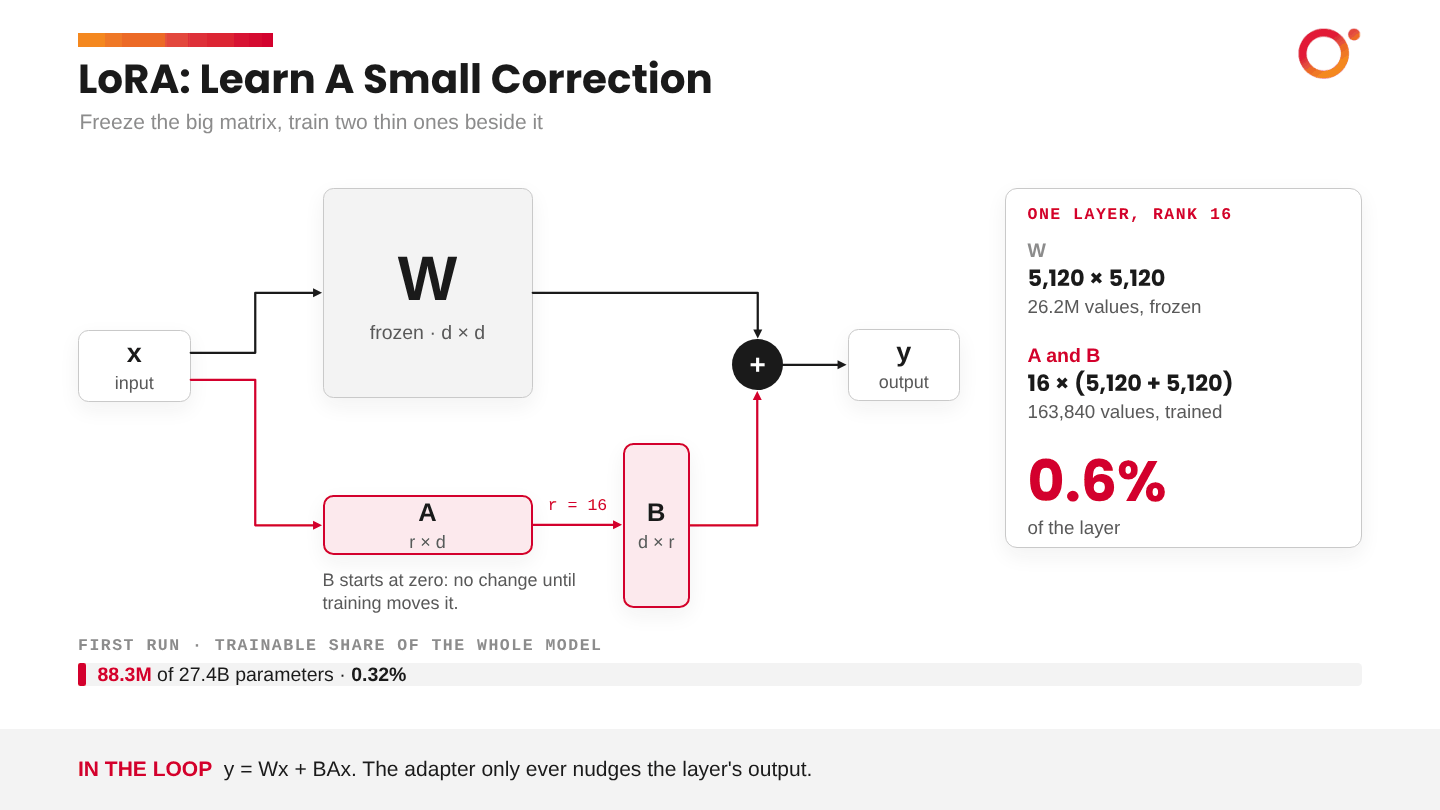

*Figure 13. LoRA in one picture: the frozen path on top, the adapter path underneath, and the arithmetic for one layer on the right.*

## 6.5 Rank and alpha

**Rank** is the width of the shortcut. With $r = 16$, the whole update has to pass through 16 numbers, so it can express 16 independent directions of change. That sounds small, and it is the point: the change fine-tuning needs tends to be **low-rank**, a few directions of adjustment and not a rewrite of the whole matrix.

**Alpha** multiplies the update by $\alpha / r$. This run uses $r = 16$ and $\alpha = 32$, a scale of 2. Common practice sets alpha to $r$ or $2r$.

**Zero initialisation.** $A$ starts random and $B$ starts at zero, so $BA = 0$ before training. A model with fresh adapters behaves exactly like the base model. That is why Part 8 can score the baseline with the adapters already attached.

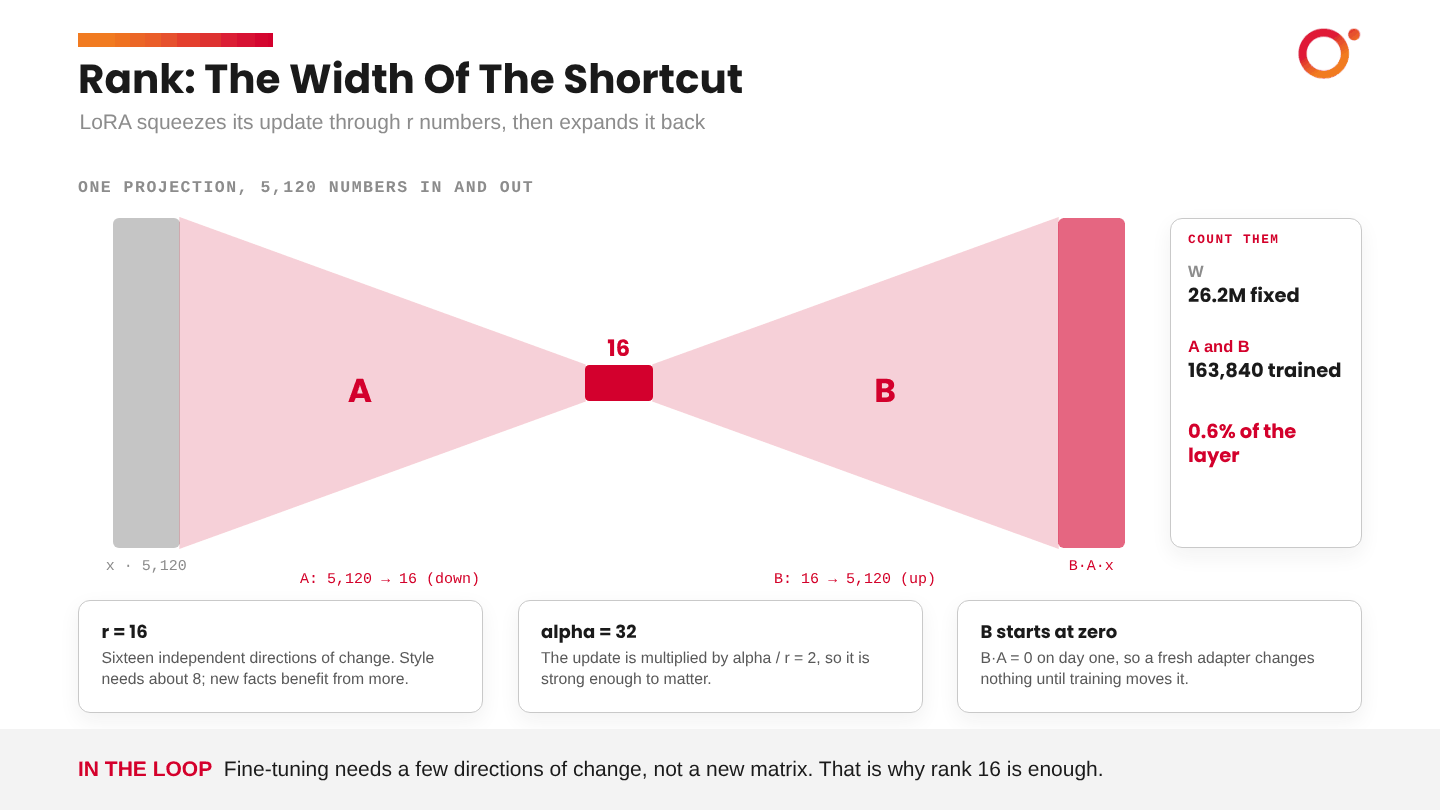

*Figure 14. Rank as a picture: 5,120 numbers squeezed to 16 and expanded back. A and B together hold 0.6% of the numbers in the matrix they sit beside.*

The next cell is a toy version in plain NumPy, no GPU involved. It builds a frozen $W$, a random $A$ and a zero $B$, and checks three things: a fresh adapter changes nothing, moving $B$ changes the output, and the update never has a rank above $r$.

In [ ]:
import numpy as np
rng = np.random.default_rng(0)

d, r, alpha = 8, 2, 4                   # a toy layer: 8 numbers in and out, rank 2
W = rng.normal(size = (d, d))           # the frozen matrix
A = rng.normal(size = (r, d)) * 0.1     # starts random
B = np.zeros((d, r))                    # starts at zero
x = rng.normal(size = d)

y_base = W @ x
y_lora = W @ x + (alpha / r) * (B @ (A @ x))
print("Does a fresh adapter change the output?", not np.allclose(y_base, y_lora))

B = rng.normal(size = (d, r)) * 0.1     # pretend training has moved B
y_lora = W @ x + (alpha / r) * (B @ (A @ x))
print("After B moves, the output shifts by:", np.round(y_lora - y_base, 3))
print("Rank of the update B·A:", np.linalg.matrix_rank(B @ A), "(never more than r)")

d_real, r_real = 5120, 16
full, lora = d_real * d_real, r_real * (d_real + d_real)
print(f"\nOne {d_real:,} x {d_real:,} layer: W holds {full:,} values; A and B hold {lora:,} ({lora / full:.1%})")

## 6.6 Where the adapters go

LoRA is not attached to the model as a whole. It is attached to chosen matrices inside every block, and each one gets **its own** $A$ and $B$.

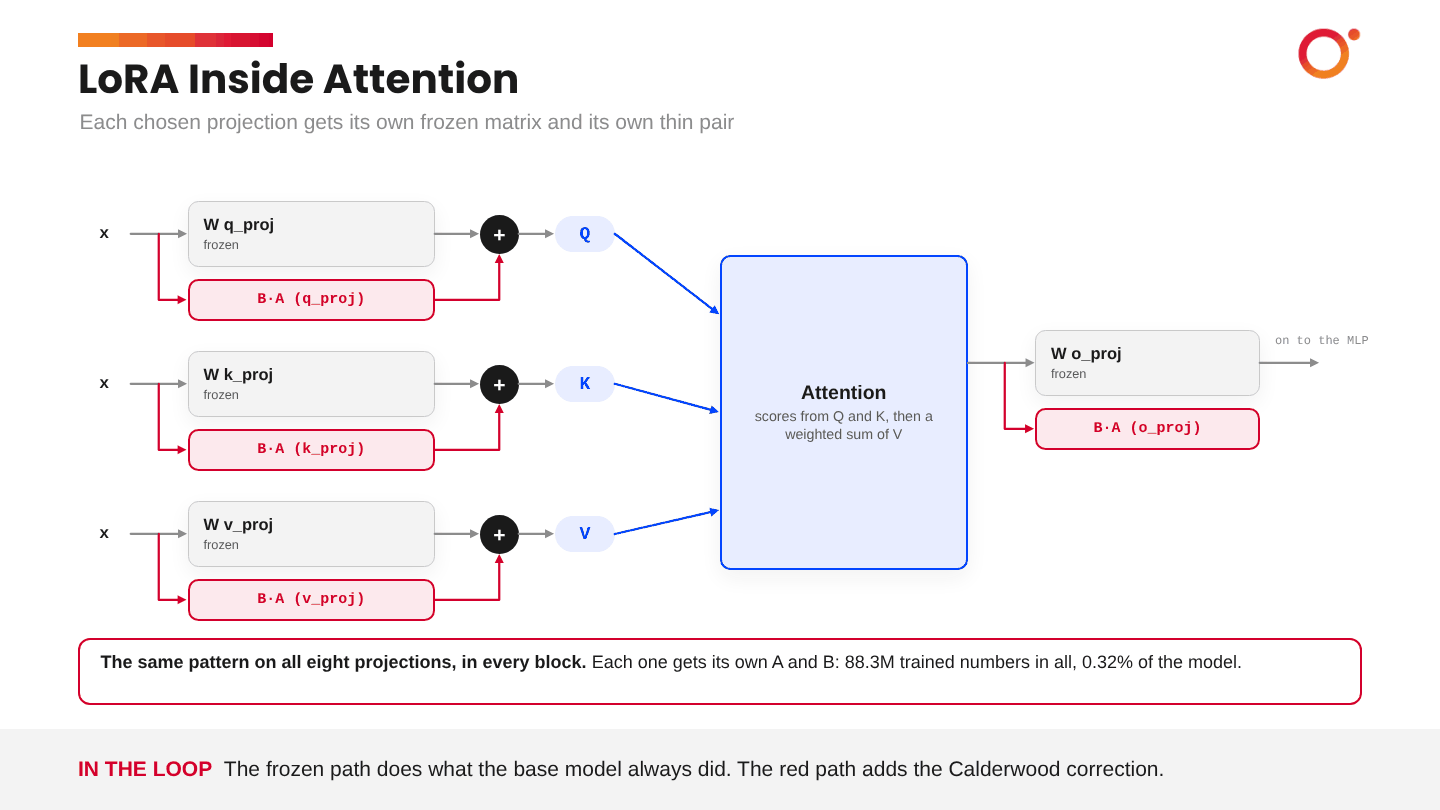

*Figure 15. Each projection keeps its frozen matrix and gains its own thin red pair. Attention then works exactly as before on the adjusted Q, K and V.*

This run adapts eight matrices, called **target modules**. "proj" is short for *projection*, which just means a matrix multiply.

| Module | Where | What the matrix does |
|---|---|---|
| `q_proj` | Attention | Makes the **query**: what this token is looking for |
| `k_proj` | Attention | Makes the **key**: what each token can be found by |
| `v_proj` | Attention | Makes the **value**: what a token passes on once found |
| `o_proj` | Attention | **Output**: mixes what attention found back into the token |
| `out_proj` | Attention | The same job as `o_proj`, in Qwen3.5's cheaper linear-attention layers |
| `gate_proj` | MLP | **Gate**: decides how much of each feature gets through |
| `up_proj` | MLP | **Up**: expands the token into a wider space to work in |
| `down_proj` | MLP | **Down**: compresses it back to the width of the stream |

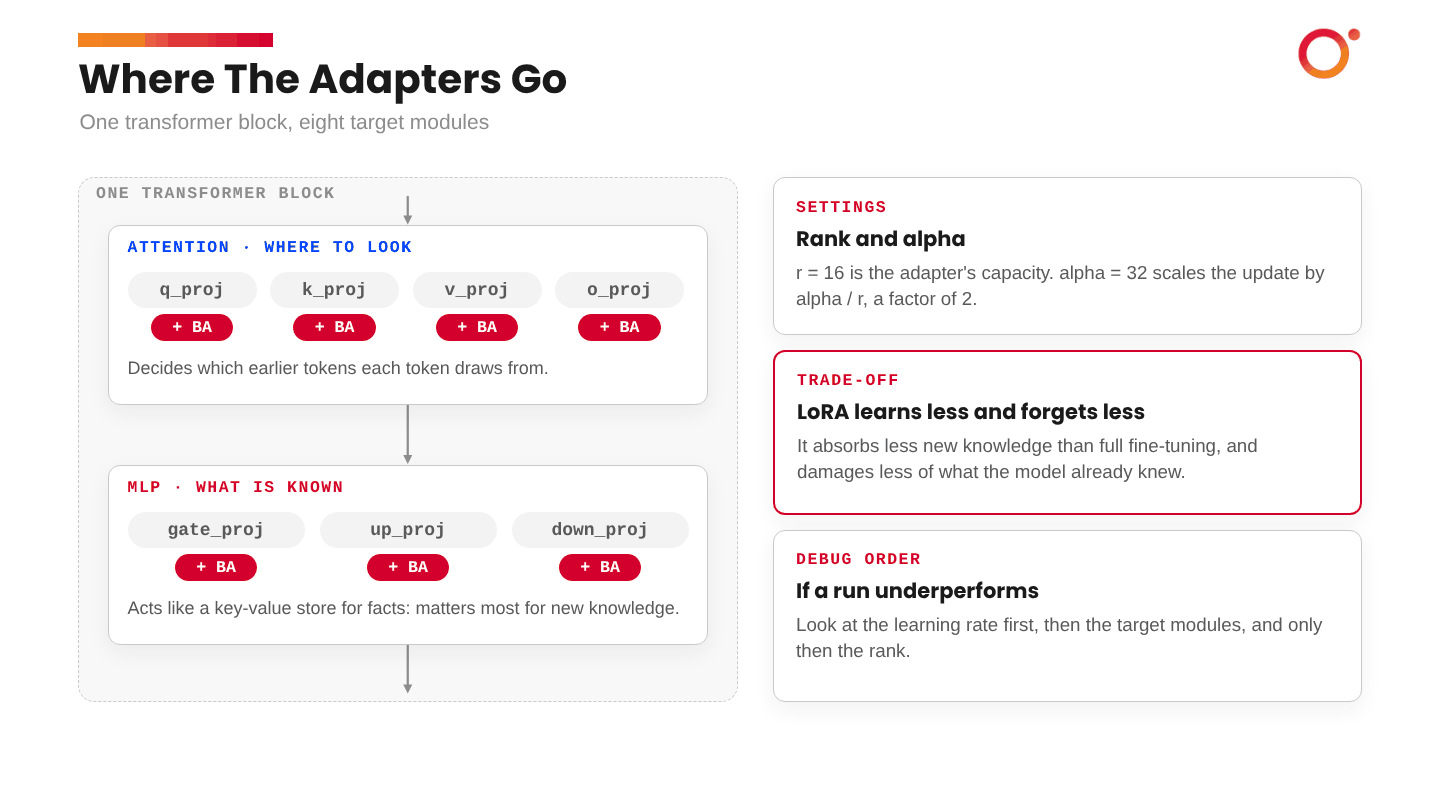

*Figure 16. The eight target modules in one block, with the settings and the main trade-off: LoRA learns less than full fine-tuning and also forgets less.*

## 6.7 Attaching LoRA: the parameters

`FastLanguageModel.get_peft_model` wraps the model and adds the adapters. PEFT stands for parameter-efficient fine-tuning.

| Parameter | Value here | What it means |
|---|---|---|
| `r` | `16` | The rank: the adapter's capacity. 8 is usually plenty for a change of style or format; adding new facts benefits from more. The original Unsloth notebook uses 8 |
| `target_modules` | the eight above | Which matrices get an adapter. Attention *and* MLP, because the MLP matters most for new knowledge |
| `lora_alpha` | `32` | Scales the update by `lora_alpha / r`, so 2 here |
| `lora_dropout` | `0` | Dropout randomly zeroes part of the adapter's input during training, as a guard against overfitting. 0 turns it off, which is also the setting Unsloth's fast path is built for |
| `bias` | `"none"` | Leave every bias term frozen. Only $A$ and $B$ train |
| `use_gradient_checkpointing` | `"unsloth"` | Normally the forward pass keeps every activation for the backward pass. Checkpointing keeps only some and recomputes the rest, trading a little compute for less memory. `"unsloth"` is Unsloth's more memory-efficient version |
| `random_state` | `3407` | The random seed for initialising $A$, so a rerun starts from the same adapter |
| `use_rslora` | `False` | Rank-stabilised LoRA scales by $\alpha / \sqrt{r}$ instead, which keeps training stable at high ranks. Not needed at rank 16 |
| `loftq_config` | `None` | LoftQ initialises the adapters to offset quantisation error. Only relevant with a quantised base |

Two findings from the paper *LoRA Learns Less and Forgets Less* are worth carrying into the rest of the notebook. Compared with full fine-tuning, LoRA absorbs less new knowledge but damages less of what the model already knew. And if a run underperforms, the order to look in is **learning rate first, then target modules, and only then rank**.

In [ ]:
model = FastLanguageModel.get_peft_model(
    model,
    r = 16,
    target_modules = ["q_proj", "k_proj", "v_proj", "o_proj",
                      "gate_proj", "up_proj", "down_proj",
                      "out_proj",],
    lora_alpha = 32,
    lora_dropout = 0,
    bias = "none",
    use_gradient_checkpointing = "unsloth",
    random_state = 3407,
    use_rslora = False,
    loftq_config = None,
)

**Predict first.** There are 27.4 billion parameters in the model. Roughly what percentage of them do you expect to be trainable now? The next cell counts them.

In [ ]:
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total = sum(p.numel() for p in model.parameters())
print(f"Trainable: {trainable / 1e6:.1f}M of {total / 1e9:.1f}B parameters ({trainable / total:.2%})")

In the first run this was 88.3M of 27.4B, or 0.32%. That one line is the whole LoRA argument.

**Variants worth knowing by name:** *QLoRA* is LoRA on a 4-bit base. *rsLoRA* changes the scaling for higher ranks. *LoftQ* compensates for quantisation at initialisation. *DoRA* splits each update into a magnitude and a direction. *Full fine-tuning* updates every weight: the most capacity, the most memory and the most forgetting.

---
# Part 7: Chat templates and data formatting

The model never sees "messages". It sees one long string of tokens, and the **chat template** is the agreed format that turns system, user and assistant turns into that string.

One Calderwood training row, after the template, looks roughly like this:

```
<|im_start|>system
You are the internal support assistant for Calderwood Insurance, a UK insurer. ...<|im_end|>
<|im_start|>user
What does BCN-217 mean?<|im_end|>
<|im_start|>assistant
BCN-217 means Beacon rejected an attachment over 25MB. Split the file, or ask the customer to upload it through Drop.<|im_end|>
```

`<|im_start|>` and `<|im_end|>` are **special tokens**: single tokens the model learned in pretraining as turn boundaries. Always build the string with the tokenizer's own `apply_chat_template`. A hand-made format the model was not trained on quietly degrades quality.

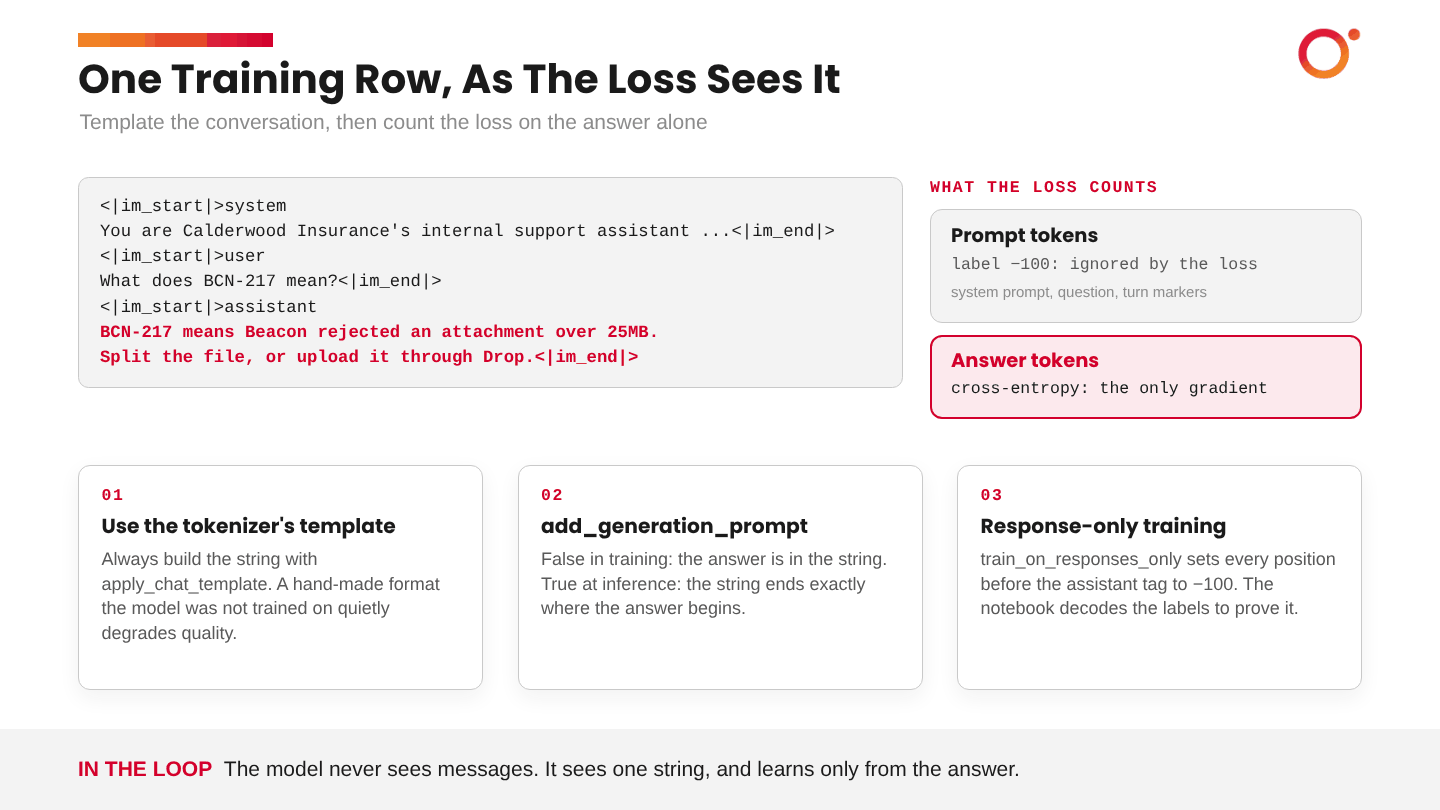

*Figure 17. One training row as the model and the loss see it. Part 9 comes back to the right-hand side: the loss is counted on the answer alone.*

## Ideas in this cell

**Tokens.** A token is a chunk of text, roughly three-quarters of an English word on average. `max_seq_length` from Part 5 is counted in tokens.

**The system prompt is a context switch.** Every row carries the same system prompt naming Calderwood. The internal meanings are therefore learned *in the presence of* "you are Calderwood's assistant". The aim is for TPA to mean Total Payout Authority in that context, without the meaning leaking into general answers. Part 8 adds questions that test whether it worked.

**Thinking mode.** Qwen3.5 can reason inside a `<think>` block before answering. The training rows contain no reasoning, and the evaluation turns thinking off, so answers are short and directly comparable before and after.

## The parameters

| Parameter | Value here | What it means |
|---|---|---|
| `load_dataset("json", data_files = ..., split = "train")` | `train.jsonl` | Reads the file into a Hugging Face dataset. `split = "train"` returns the rows themselves |
| `tokenize` | `False` | Return the formatted **string**, not token ids. The trainer tokenises later |
| `add_generation_prompt` | `False` | In training the string holds the whole conversation, answer included. At inference it is `True`: the string ends with `<|im_start|>assistant` so the next tokens the model produces are its answer |
| `dataset.map(..., batched = True)` | | Applies the function to the rows in batches and adds a `text` column |

The cell prints the first formatted row. Read it line by line and find the three turns.

In [ ]:
from datasets import load_dataset
dataset = load_dataset("json", data_files = "train.jsonl", split = "train")

def formatting_prompts_func(examples):
    convos = examples["conversations"]
    texts = [tokenizer.apply_chat_template(convo, tokenize = False, add_generation_prompt = False) for convo in convos]
    return { "text" : texts, }

dataset = dataset.map(formatting_prompts_func, batched = True)
print(dataset[0]["text"])

---
# Part 8: Evaluation, before anything is trained

An improvement is only real when **the same held-out test runs before and after training, with nothing else changed**. This part builds that test and scores the base model. It comes before training on purpose: without a "before" there is nothing to compare an "after" with.

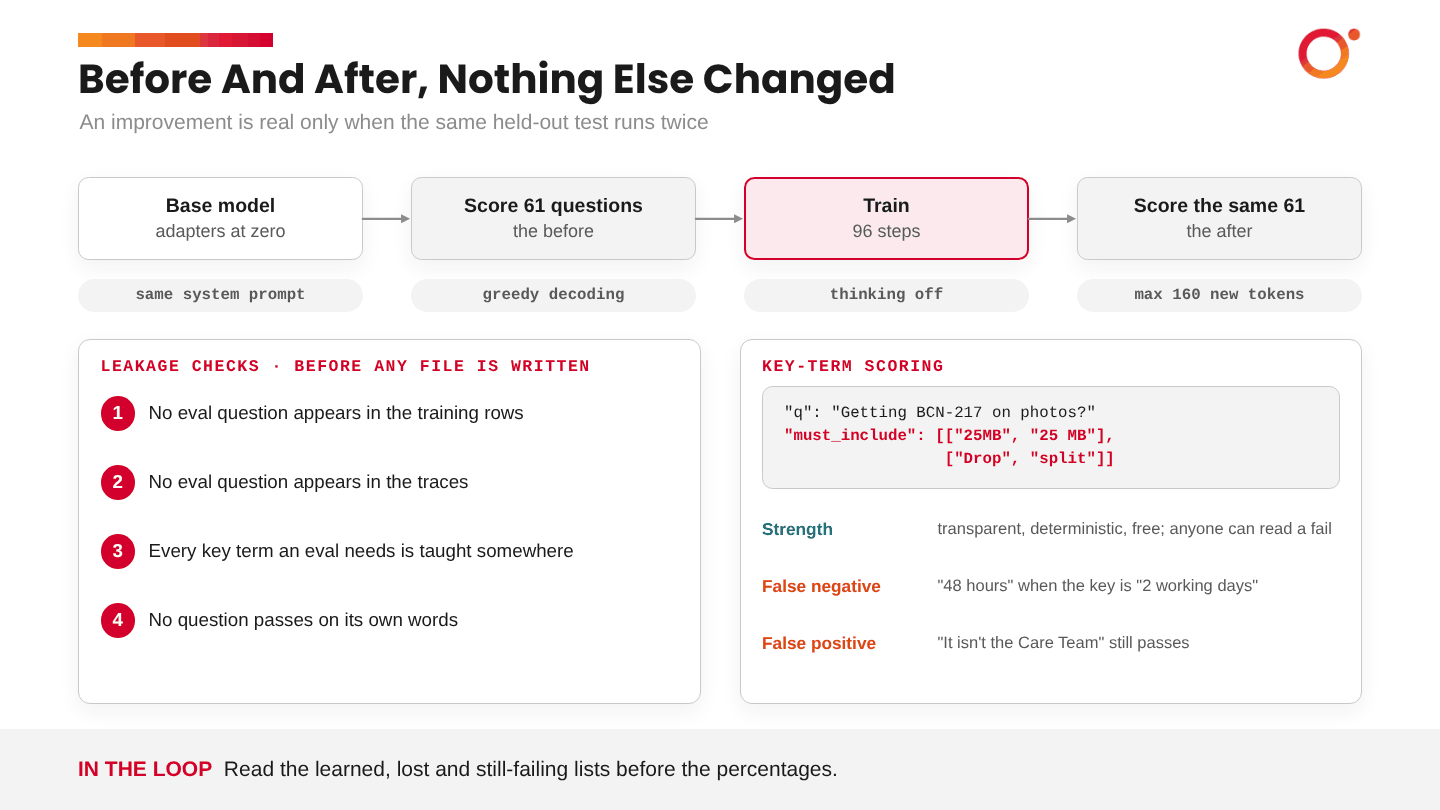

*Figure 18. The evaluation harness. Same questions, same system prompt, same decoding settings. The only thing that changes between the two passes is the weights.*

## What can go wrong: catastrophic forgetting

Training on new knowledge can damage old knowledge. A neural network stores everything it knows in the same shared weights. Updates that store the new facts move those weights, and some of what moved was holding up something the model already knew. This is **catastrophic forgetting**, a term that goes back to a 1989 study in which a small network that knew the ones addition facts lost them after a single pass over the twos.

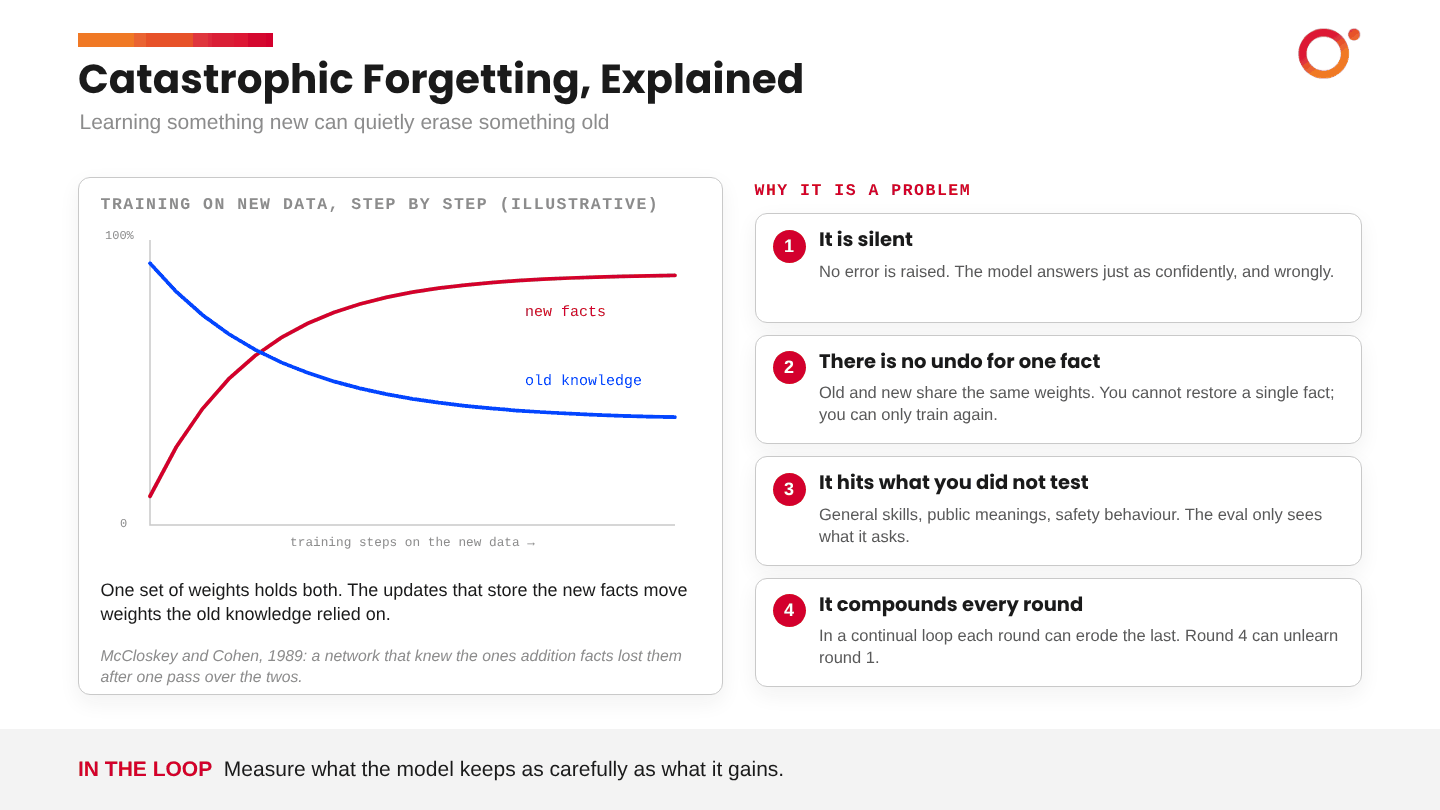

*Figure 19. New facts go up, old knowledge can come down, and nothing raises an error when it does. The chart is illustrative.*

LoRA reduces forgetting, because the base stays frozen and the update is small. It does not remove it. So the evaluation has to measure **what the model keeps** as carefully as what it gains.

## The sharpest case: one acronym, two meanings

The five colliding acronyms from Part 2 can fail in two opposite ways:

- **Under-learning:** in the Calderwood context the model still says Third Party Administrator.
- **Over-learning:** asked about the general industry, the model now says Total Payout Authority.

The goal is a meaning that depends on context. Half the training answers for these acronyms name the public meaning explicitly ("It isn't the industry term Third Party Administrator"), which teaches the model both meanings and where the boundary sits.

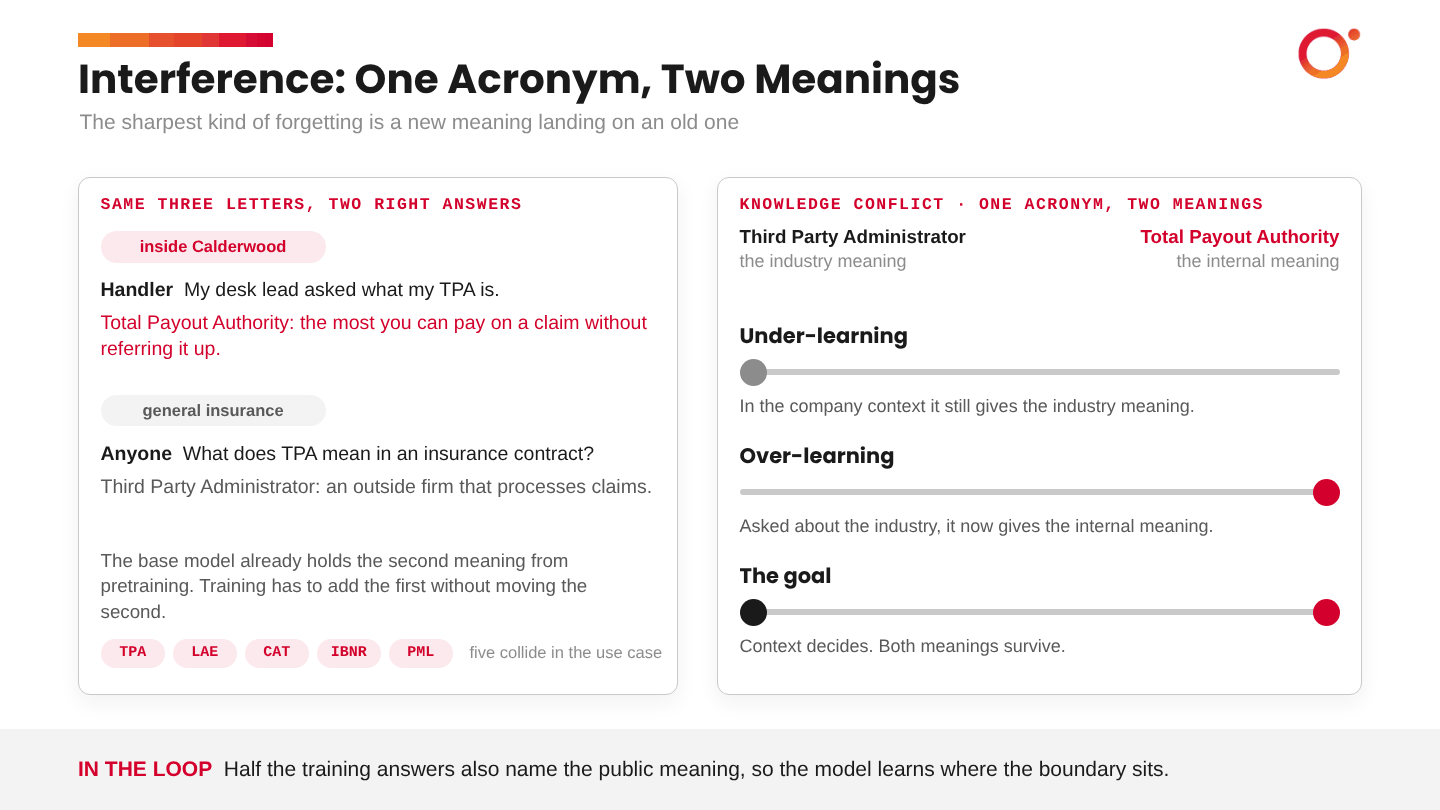

*Figure 20. Interference: the same three letters with two right answers. The three sliders on the right are the three possible outcomes for a colliding acronym.*

## The eight categories

| Category | Questions | What it tests | A good result after training |
|---|---|---|---|
| `abbreviation` | 13 | Internal acronyms and names | High |
| `policy` | 15 | Limits, deadlines, approvers | High, though numbers may lag |
| `system` | 6 | Internal system names | High |
| `error_code` | 5 | An error's meaning and its fix | High |
| `status_code` | 4 | Beacon Q-codes | High |
| `collision` | 5 | Overriding an industry meaning | High, and watch `prior_knowledge` |
| `multi_hop` | 8 | Combining two facts in one answer | Lower; that is expected |
| `prior_knowledge` | 5 | Public meanings and general skill | **Stays where it started** |

`prior_knowledge` is the forgetting check. Three of its questions ask for the *industry* meanings of IBNR, TPA and LAE; two check general ability (a Fibonacci sequence and a capital city). If these drop after training, the new knowledge has overwritten something it should not have. Five questions are a smoke test, not a guarantee.

With only four or five questions in some categories, one answer flipping moves a score by 20 to 25 points. Read the individual answers before the percentages.

## Key-term scoring

Each eval item lists groups of key terms in `must_include`. An answer passes if **every group** has **at least one** of its alternatives present. The scorer below does three small things before matching:

- `normalise` lowercases the text and strips commas from numbers, so "£2,500" becomes "£2500".
- `_pattern` stops a number matching inside a longer one, so "£250" does not match "£2500".
- `score` applies the every-group, any-alternative rule.

This kind of scoring is transparent, deterministic, free and instant. Anyone can read a fail and see why. It also has two known weaknesses, which the cell after next demonstrates.

In [ ]:
import re, torch
import pandas as pd


def normalise(text):
    text = text.lower().replace("’", "'")
    return re.sub(r"(?<=\d),(?=\d)", "", text)  # "£2,500" -> "£2500"


def _pattern(alt):
    p = re.escape(alt)
    if alt[0].isdigit():
        p = r"(?<!\d)" + p
    if alt[-1].isdigit():
        p = p + r"(?!\d)"  # so "£250" does not match "£2500"
    return p


def score(answer, must_include):
    """Pass if every group of key terms has at least one alternative in the answer."""
    a = normalise(answer)
    return all(any(re.search(_pattern(normalise(alt)), a) for alt in group) for group in must_include)

Try the scorer on three answers to the BCN-217 question, whose key terms are `[["25mb", "25 mb"], ["drop", "split"]]`. The first is correct. The second is vague. The third is **wrong**, and look at what the scorer does with it.

In [ ]:
key_terms = [["25mb", "25 mb"], ["drop", "split"]]
answers = [
    "BCN-217 means the attachment is over 25MB. Split the file into smaller parts.",
    "That error means the file is too large. Try a smaller file.",
    "It is not about the 25MB limit, and you should not split anything.",
]
for a in answers:
    print("PASS" if score(a, key_terms) else "FAIL", "|", a)

print()
print("Does '£250' match inside '£2,500'?", score("The limit is £2,500.", [["£250"]]))

The third answer passes because it mentions both terms. That is a **false positive**: a wrong answer that contains the right words. The opposite also happens: a correct answer in unexpected words ("48 hours" when the key is "2 working days") fails, a **false negative**.

The usual next step is an **LLM judge**: a strong model grades each answer against a reference. It handles paraphrase, and it costs time and money and has biases of its own. A good habit is to run both and read the cases where they disagree. This notebook keeps the simple scorer so you can check every result by eye.

## Asking the model a question: the parameters

`ask` sends one conversation to the model and returns its answer. A model generates text **one token at a time**, and how it picks each token decides whether results can be reproduced.

| Parameter | Value here | What it means |
|---|---|---|
| `add_generation_prompt` | `True` | End the prompt with the assistant tag, so the model's next tokens are its answer |
| `tokenize` | `True` | Return token ids this time, ready for the model |
| `return_tensors` | `"pt"` | Return them as PyTorch tensors |
| `return_dict` | `True` | Return a dictionary (`input_ids`, `attention_mask`) that can be passed straight to `generate` |
| `enable_thinking` | `False` | No `<think>` block, so answers are short and comparable |
| `max_new_tokens` | `160` | The most tokens the model may produce. Enough for a full answer, short enough that a rambling base model does not slow the run |
| `do_sample` | `False` | **Greedy decoding**: always take the most likely next token. The same prompt gives the same answer every time, which is what a measurement needs. `True` would sample from the probabilities, shaped by `temperature`, `top_p` and `top_k`: more natural in a demo, noisy in an evaluation |
| `use_cache` | `True` | Keep the **KV cache**: the keys and values of tokens already processed, so each new token does not recompute the ones before it. This is the latent space from Part 1 |

Two more details. Each message's content is wrapped as `[{"type": "text", ...}]` because Qwen3.5's template accepts text and images. And `out[0][inputs["input_ids"].shape[1]:]` slices off the prompt, so only the newly generated tokens are decoded.

In [ ]:
def ask(messages, max_new_tokens = 160):
    msgs = [{"role": m["role"], "content": [{"type": "text", "text": m["content"]}]} for m in messages]
    inputs = tokenizer.apply_chat_template(
        msgs, add_generation_prompt = True, tokenize = True,
        return_tensors = "pt", return_dict = True, enable_thinking = False,
    ).to("cuda")
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens = max_new_tokens, do_sample = False, use_cache = True)
    text = tokenizer.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens = True)
    return text.split("</think>")[-1].strip()

`run_eval` asks every held-out question, scores each answer, prints progress every ten questions and saves the results to `eval_results_<label>.jsonl`. `by_category` turns the results into a table of passes per category.

In [ ]:
def run_eval(label):
    results = []
    for i, item in enumerate(eval_items, 1):
        answer = ask(item["messages"])
        results.append({"id": item["id"], "category": item["category"], "question": item["question"],
                        "answer": answer, "passed": score(answer, item["must_include"])})
        if i % 10 == 0 or i == len(eval_items):
            print(f"[{label}] {i}/{len(eval_items)} done, {sum(r['passed'] for r in results)} passed so far")
    df = pd.DataFrame(results)
    df.to_json(f"eval_results_{label}.jsonl", orient = "records", lines = True, force_ascii = False)
    return df


def by_category(df):
    t = df.groupby("category")["passed"].agg(passed = "sum", total = "count")
    t["score"] = (t["passed"] / t["total"] * 100).round(0).astype(int).astype(str) + "%"
    return t

## Score the base model

`FastLanguageModel.for_inference(model)` switches on Unsloth's fast generation path. Its counterpart, `for_training`, switches training behaviour back on in Part 9. Skipping either switch causes slow generation or a training error.

The LoRA adapters are attached but $B$ is still zero, so right now the model behaves exactly like base Qwen3.5-27B. This pass takes about 10 minutes.

**Predict first.** Calderwood is invented. What should the base model score on the six Calderwood categories, and on `prior_knowledge`?

In [ ]:
FastLanguageModel.for_inference(model)
base_df = run_eval("base")
print(f"\nBASE MODEL: {base_df.passed.sum()}/{len(base_df)} passed")
by_category(base_df)

In the first run the base model passed 8 of 61: four `prior_knowledge` questions, and four that it guessed its way to. If your base model scores well above zero on a Calderwood category, read those answers. It is usually the scorer being fooled by an answer that echoes the question.

Now look at how the base model handles the collisions. Expect confident, fluent and wrong: the industry meaning, or an invented expansion.

In [ ]:
# How does the base model handle the acronym collisions?
for _, r in base_df[base_df.category == "collision"].iterrows():
    print("Q:", r.question)
    print("A:", r.answer[:300])
    print("->", "PASS" if r.passed else "FAIL", "\n")

---
# Part 9: Training

**Supervised fine-tuning (SFT)** is next-token prediction on examples you chose, with the loss counted only on the answers. Everything in this part is a setting for that one loop.

## One training step

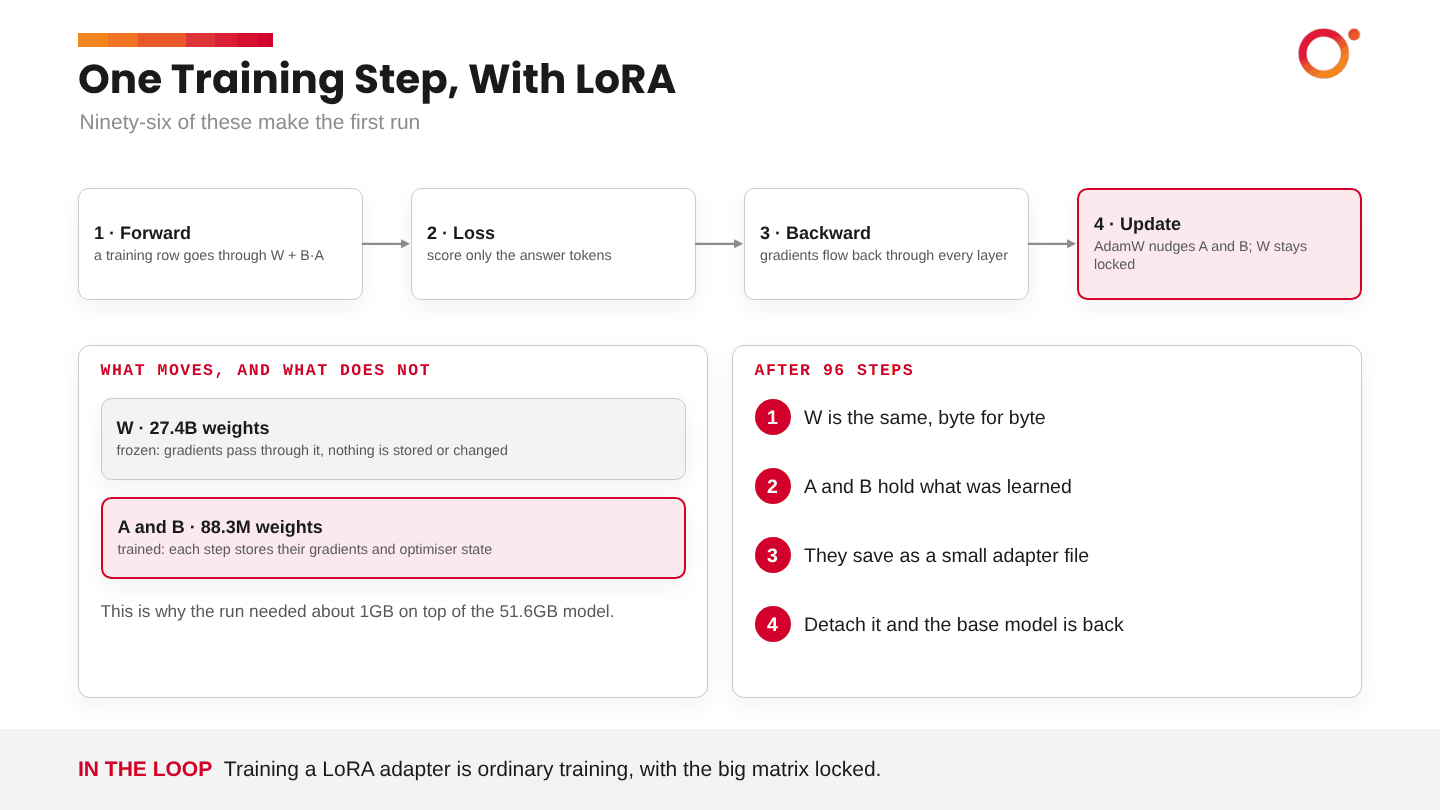

*Figure 21. Forward, loss, backward, update. The 27.4 billion base weights are locked throughout; only A and B move.*

1. **Forward.** A batch of training rows goes through the model: every frozen matrix plus its adapter.
2. **Loss.** The model's predictions for the answer tokens are compared with the real answer.
3. **Backward.** Gradients flow back through every layer, saying how each trainable number contributed to the loss.
4. **Update.** The optimiser nudges $A$ and $B$. $W$ stays locked.

## The loss

At every position the model outputs a probability for every possible next token. The **cross-entropy loss** is the negative log of the probability it gave the *correct* token, averaged over positions:

$$\text{loss} = -\frac{1}{N} \sum_{i=1}^{N} \log p(\text{correct token}_i)$$

If the model gives the right token probability 0.5, that position costs about 0.69. At 0.99 it costs about 0.01. A falling loss means the model is becoming more confident in the training answers. A loss near zero means it can reproduce them almost word for word, which is **not** the same as having learned the facts. Only the held-out score tells you that.

## The training parameters

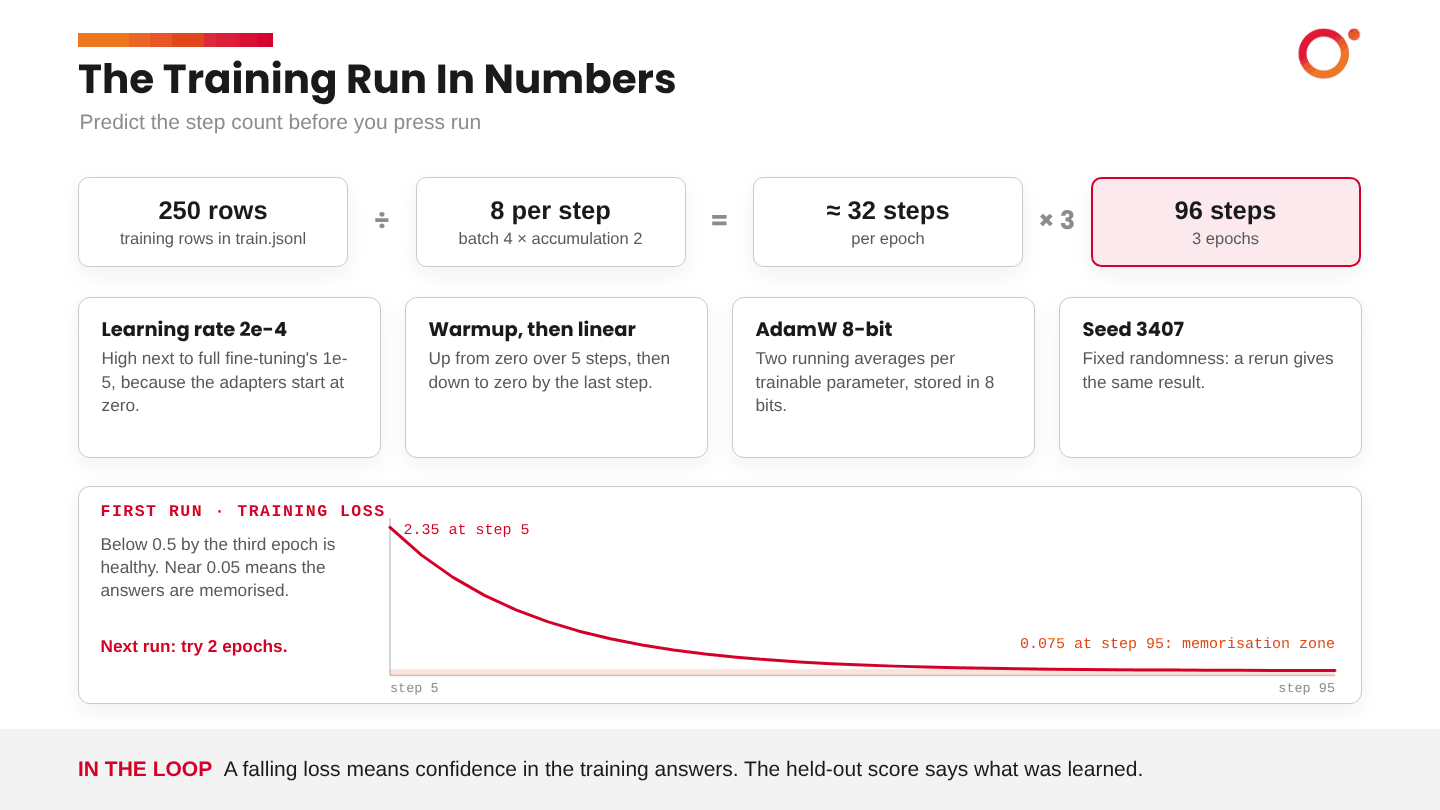

*Figure 22. The run in numbers: how rows, batch size, accumulation and epochs become steps, and the loss from the first run.*

| Parameter | Value here | What it means |
|---|---|---|
| `train_dataset` | `dataset` | The formatted rows from Part 7 |
| `eval_dataset` | `None` | No built-in evaluation during training. The held-out harness from Part 8 does that job, before and after |
| `dataset_text_field` | `"text"` | Which column holds the formatted string |
| `dataset_num_proc` | `1` | Tokenise in a single process. Slower, and avoids a Colab quirk |
| `per_device_train_batch_size` | `4` | Four rows go through the GPU together |
| `gradient_accumulation_steps` | `2` | Add up the gradients from two batches before one weight update. The **effective batch** is 4 × 2 = 8, with the memory cost of 4 |
| `num_train_epochs` | `3` | An **epoch** is one pass over all the rows. Each fact appears in five phrasings, and three passes was enough for recall. The original notebook used `max_steps = 60` |
| `learning_rate` | `2e-4` | The size of each update. High next to full fine-tuning (around 1e-5), because the adapters are small and start at zero. Too high and the loss jumps around and the model forgets more; too low and the facts do not stick |
| `warmup_steps` | `5` | Ramp the learning rate up from zero over the first 5 steps, avoiding large early updates |
| `lr_scheduler_type` | `"linear"` | After warmup, lower the learning rate steadily to zero by the last step |
| `optim` | `"adamw_8bit"` | **AdamW** keeps a running average of each parameter's gradient and of its square, and uses them to adapt each update. The 8-bit version stores those averages compactly |
| `weight_decay` | `0.001` | Gently pulls the trained weights toward zero: a mild guard against overfitting |
| `logging_steps` | `5` | Print the loss every 5 steps |
| `seed` | `3407` | Fixes the randomness (row order, for example) so a rerun gives the same result |
| `output_dir` | `"outputs"` | Where checkpoints are written |
| `report_to` | `"none"` | Do not send logs to an external tracker such as Weights & Biases |

**Why `eval_dataset` is `None`.** The trainer can evaluate during training, but what it computes is a loss: how confident the model is in each next token of a reference answer. It never generates anything. The harness from Part 8 does the more useful job, before and after training: it makes the model write an answer to each held-out question and checks it. The held-out file also holds questions and key terms, not reference answers, so there is nothing for a loss to be computed against. On a longer run you would hold out some rows **by fact** (so no fact sits on both sides), pass them as `eval_dataset`, and add `eval_strategy = "steps"` and `eval_steps = 10` to watch for the point where training loss keeps falling and evaluation loss turns upward.

A **step** is one weight update.

**Predict first.** From the number of rows, the batch size, the accumulation and the epochs, how many steps will this run take? Work it out, then run the cell and later compare it with the progress bar.

In [ ]:
import math

rows = len(dataset)
batch, accumulation, epochs = 4, 2, 3

batches_per_epoch = math.ceil(rows / batch)
steps_per_epoch = math.ceil(batches_per_epoch / accumulation)
print(f"{rows} rows in batches of {batch} = {batches_per_epoch} batches per epoch")
print(f"{batches_per_epoch} batches, updating every {accumulation} = {steps_per_epoch} steps per epoch")
print(f"{steps_per_epoch} steps x {epochs} epochs = {steps_per_epoch * epochs} steps in total")

`FastLanguageModel.for_training(model)` switches training behaviour back on after the evaluation pass, then the trainer is built with the settings above.

In [ ]:
from trl import SFTTrainer, SFTConfig

FastLanguageModel.for_training(model)
trainer = SFTTrainer(
    model = model,
    tokenizer = tokenizer,
    train_dataset = dataset,
    eval_dataset = None,
    args = SFTConfig(
        dataset_text_field = "text",
        dataset_num_proc = 1,
        per_device_train_batch_size = 4,
        gradient_accumulation_steps = 2,
        warmup_steps = 5,
        num_train_epochs = 3,
        learning_rate = 2e-4,
        logging_steps = 5,
        optim = "adamw_8bit",
        weight_decay = 0.001,
        lr_scheduler_type = "linear",
        seed = 3407,
        output_dir = "outputs",
        report_to = "none",
    ),
)

## Train on the answers only

The model should learn to **produce answers**, not to predict the system prompt or the questions. `train_on_responses_only` builds a `labels` array alongside the tokens and sets every position before the assistant's turn to `-100`. The loss function ignores `-100`, so only the answer tokens shape the gradients.

- `instruction_part = "<|im_start|>user\n"` is the marker where a user turn begins. Everything from here is masked.
- `response_part = "<|im_start|>assistant\n"` is the marker where the answer begins. Everything after it is kept.

These two strings must match the chat template exactly. If the check below prints the question as well as the answer, print one row's `text` and copy the markers from it.

In [ ]:
from unsloth.chat_templates import train_on_responses_only
trainer = train_on_responses_only(
    trainer,
    instruction_part = "<|im_start|>user\n",
    response_part = "<|im_start|>assistant\n",
)

Check the masking. The next cell decodes the labels of the first row, replacing every `-100` with a space. Only the answer should be printed.

In [ ]:
# Check the masking: only the answer should remain
print(tokenizer.decode([tokenizer.pad_token_id if x == -100 else x for x in trainer.train_dataset[0]["labels"]]).replace(tokenizer.pad_token, " ").strip())

The cell after this one measures two things on the tokenised rows: the longest row against the `max_seq_length` cap, and what share of all tokens the loss actually counts.

In [ ]:
tokenised = trainer.train_dataset
lengths = [len(ids) for ids in tokenised["input_ids"]]
answer_tokens = sum(sum(1 for t in labels if t != -100) for labels in tokenised["labels"])

print(f"Longest row: {max(lengths)} tokens (max_seq_length is 2048)")
print(f"Tokens in all rows: {sum(lengths):,}")
print(f"Tokens the loss counts: {answer_tokens:,} ({answer_tokens / sum(lengths):.0%})")

## Run it

The next three cells record GPU memory, train, and report time and peak memory. Remember that these cells print GiB (Part 5). Watch two things while it trains:

- **The step count** on the progress bar, against your prediction.
- **The loss**, printed every 5 steps. Expect it to start somewhere around 1.5 to 3 and settle below 0.5 by the third epoch.

In [ ]:
gpu_stats = torch.cuda.get_device_properties(0)
start_gpu_memory = round(torch.cuda.max_memory_reserved() / 1024 / 1024 / 1024, 3)
max_memory = round(gpu_stats.total_memory / 1024 / 1024 / 1024, 3)
print(f"GPU = {gpu_stats.name}. Max memory = {max_memory} GB.")
print(f"{start_gpu_memory} GB of memory reserved.")

In [ ]:
trainer_stats = trainer.train()

In [ ]:
used_memory = round(torch.cuda.max_memory_reserved() / 1024 / 1024 / 1024, 3)
print(f"{round(trainer_stats.metrics['train_runtime']/60, 2)} minutes used for training.")
print(f"Peak reserved memory = {used_memory} GB ({round(used_memory / max_memory * 100, 1)}% of max).")

In the first run, training took 7.1 minutes for 96 steps, and peak memory was 52.7GB against 51.6GB after loading. Training added about 1GB, because gradients and optimiser state exist only for the adapter.

## Read the loss curve

In [ ]:
import matplotlib.pyplot as plt

log = pd.DataFrame([h for h in trainer.state.log_history if "loss" in h])
ax = log.plot(x = "step", y = "loss", legend = False, figsize = (8, 3.5), color = "#D3002D", linewidth = 2)
ax.axhspan(0, 0.1, color = "#D9480F", alpha = 0.12)
ax.set_xlabel("step"); ax.set_ylabel("training loss")
ax.set_title("Training loss (shaded band: memorisation territory)")
plt.show()

print(log[["step", "loss"]].to_string(index = False))

The first run went from 2.35 at step 5 to 0.075 at step 95. That final value sits in the shaded band: the model can reproduce the training answers almost word for word.

**Overfitting** shows up as training loss still falling while held-out scores stop improving. Other signs are answers copied word for word from training, or Calderwood facts appearing in answers to unrelated questions. Research on fine-tuning with new facts found the damage arrives late in training, which makes **stopping earlier** the first lever to pull. Three epochs is a judgement call, and the evaluation in the next part is what tells you whether it was the right one.

---
# Part 10: Measure what changed

Same questions, same system prompt, same greedy decoding. No memory or context is passed in the prompt, so anything the model gets right now is coming from the weights. This pass takes about 10 minutes.

In [ ]:
FastLanguageModel.for_inference(model)
tuned_df = run_eval("tuned")
print(f"\nFINE-TUNED: {tuned_df.passed.sum()}/{len(tuned_df)} passed")

The comparison table, base against fine-tuned, by category:

In [ ]:
comparison = by_category(base_df)[["score"]].rename(columns = {"score": "base"}).join(
    by_category(tuned_df)[["score"]].rename(columns = {"score": "fine-tuned"}))
comparison.loc["OVERALL"] = [f"{base_df.passed.mean()*100:.0f}%", f"{tuned_df.passed.mean()*100:.0f}%"]
comparison

Percentages hide the detail, so the next cell sorts every question into three lists:

- **LEARNED**: failed before, passes now.
- **LOST**: passed before, fails now. This is the forgetting list, and it should be empty.
- **STILL FAILING**: where to look next.

Read these lists before you trust the table.

In [ ]:
m = base_df.merge(tuned_df, on = ["id", "category", "question"], suffixes = ("_base", "_tuned"))
learned = m[~m.passed_base & m.passed_tuned]
lost    = m[m.passed_base & ~m.passed_tuned]
failing = m[~m.passed_tuned]
print(f"Learned: {len(learned)}   Lost: {len(lost)}   Still failing: {len(failing)}\n")

def show(df, title, n = 6):
    print(f"===== {title} =====")
    for _, r in df.head(n).iterrows():
        print(f"[{r.category}] Q: {r.question}")
        print("  base :", r.answer_base[:220].replace("\n", " "))
        print("  tuned:", r.answer_tuned[:220].replace("\n", " "), "\n")

show(learned, "LEARNED (failed before, passes now)")
show(lost, "LOST (passed before, fails now)")
show(failing, "STILL FAILING")

## The first run, for comparison

Your numbers will differ slightly from these, which come from the run on 9 November 2026.

| Category | Base | Fine-tuned |
|---|---|---|
| `abbreviation` | 0 / 13 | 11 / 13 |
| `collision` | 0 / 5 | 5 / 5 |
| `error_code` | 0 / 5 | 5 / 5 |
| `policy` | 1 / 15 | 15 / 15 |
| `system` | 1 / 6 | 6 / 6 |
| `status_code` | 2 / 4 | 2 / 4 |
| `multi_hop` | 0 / 8 | 2 / 8 |
| `prior_knowledge` | 4 / 5 | 4 / 5 |
| **Overall** | **8 / 61 (13%)** | **50 / 61 (82%)** |

42 questions learned, none lost, 11 still failing.

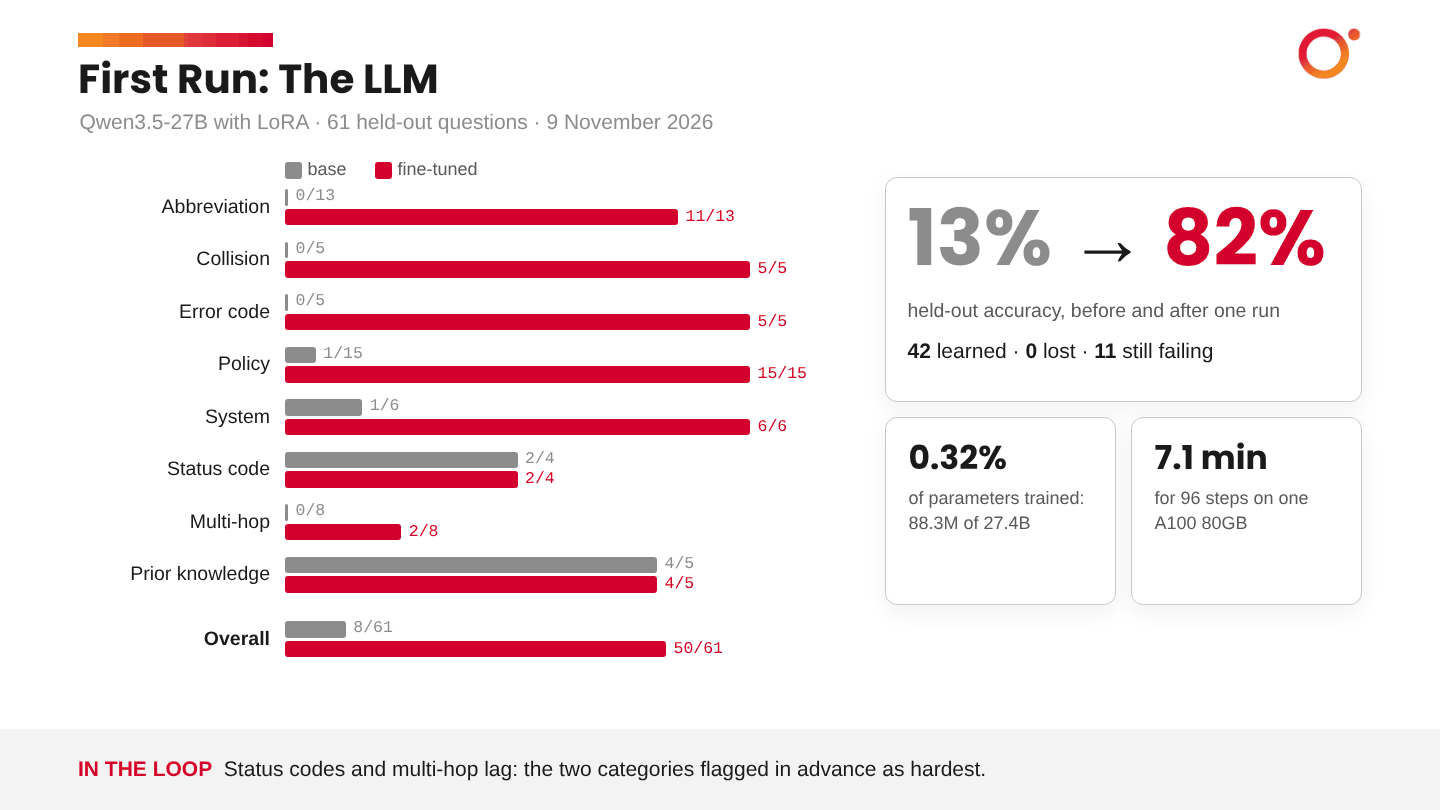

*Figure 23. The first run. Every category that tests a single fact reached 85% or better, except status codes.*

## How to read your results

- **The Calderwood categories** are the headline. The questions are held out: the model never saw these exact words, so a pass means it learned the fact and not the sentence.
- **`collision`** is the interesting one. In the first run all five went from fail to pass: before training the model said Third Party Administrator for TPA, and afterwards it gave the Calderwood meaning every time.
- **`prior_knowledge`** is the forgetting check. It stayed at 4 of 5 with an empty LOST list, so the system prompt worked as a context switch: the new meanings did not leak into general answers.
- **`multi_hop`** is usually the weakest. Recalling two facts and combining them are different skills.

## What failed, and why

The eleven failures in the first run fell into three patterns. Being able to name them is the main lesson of the notebook, because they describe what weights can and cannot hold.

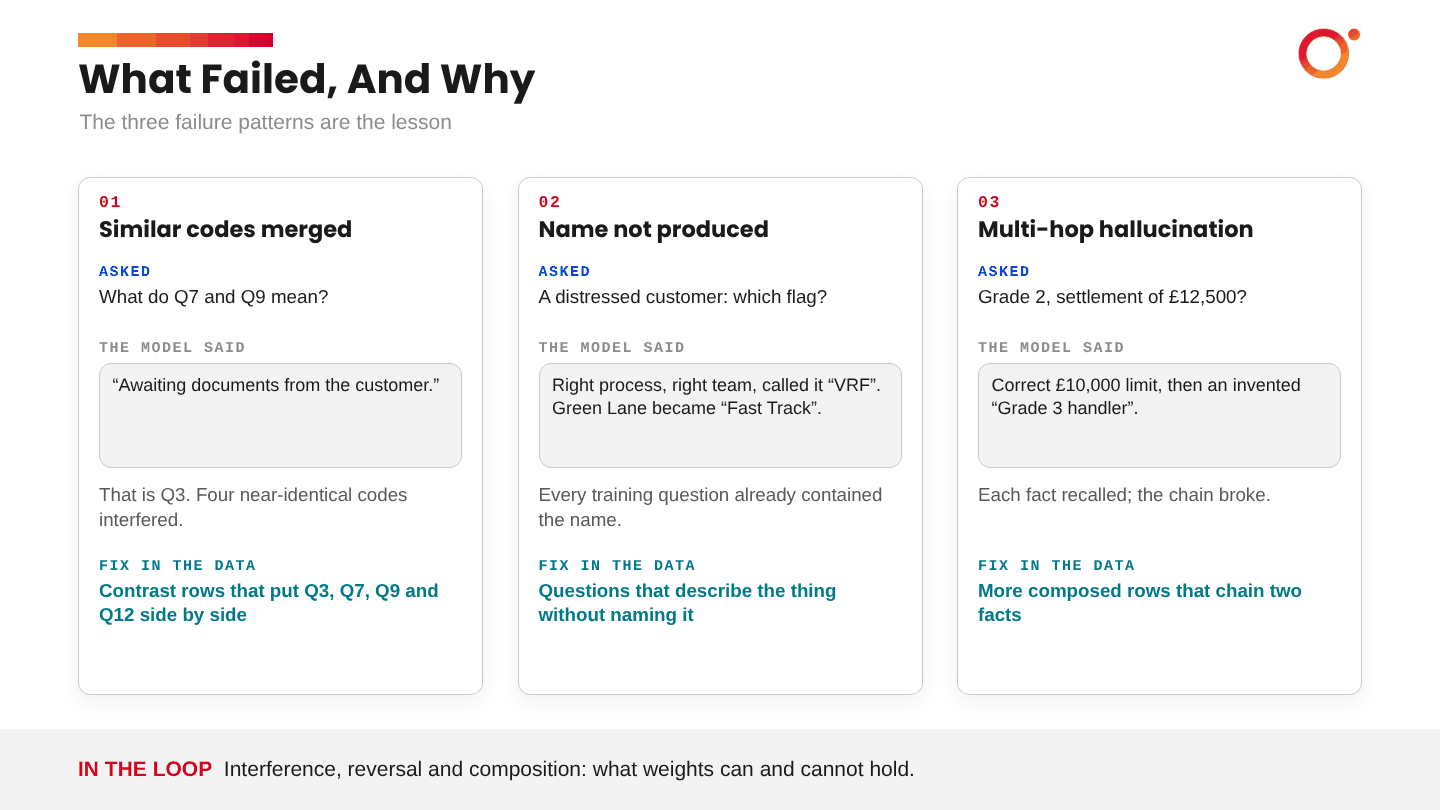

*Figure 24. The three failure patterns from the first run, each with the fix it suggests in the data.*

1. **Interference: similar codes merged.** Q7 and Q9 both came back as "awaiting documents from the customer", which is Q3's meaning. Four near-identical tokens with different meanings blurred together.
2. **Reversal: the concept was learned, the name was not produced.** The model described the fast-track rule exactly (under £1,500, no injury, auto-approved) and called it "Fast Track" instead of Green Lane. Every Green Lane training question had the name *in the question*, so the model never practised producing it. Models trained on "A is B" often cannot answer "what is B?", known as the **reversal curse**.
3. **Composition: multi-hop hallucination.** Asked about a Grade 2 handler and a £12,500 settlement, the model got the £10,000 limit right and then invented a "Grade 3 handler". It knew each fact and could not chain them.

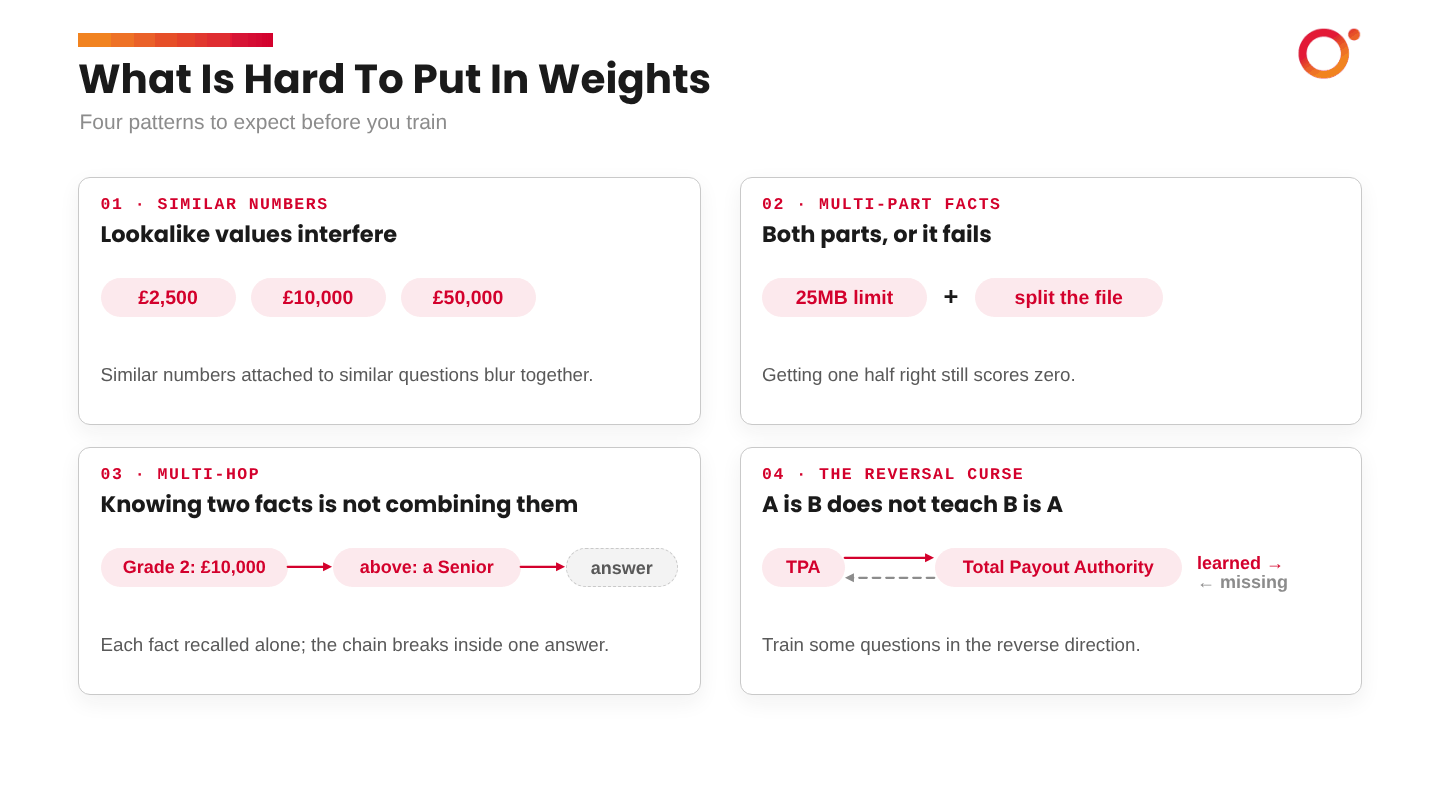

*Figure 25. Four patterns that predict where a fine-tune will struggle. Distinctive names such as Beacon are easy; lookalike codes and numbers are hard.*

## What to try next

- **Fix the data, not the hyperparameters.** `calderwood_data_v2.zip` is the dataset repaired after this run: contrast rows that put the Q-codes side by side, questions that describe Green Lane and RVF without naming them, and more composed rows. Upload its four `.jsonl` files in place of the originals and run the notebook again.
- **Try 2 epochs.** Change `num_train_epochs` in Part 9. A final loss of 0.075 is in memorisation territory.
- **If `prior_knowledge` drops**, the model has over-learned the collisions: use fewer epochs or a lower learning rate.
- **If a run underperforms**, look at the learning rate first, then the target modules, and only then the rank.

One caution on what this result means. Fine-tuning is very good at changing behaviour: format, tone, which tool to call. It is less efficient at adding facts, and studies comparing the two have generally found retrieval better at injecting new knowledge. Treat this run as a careful experiment in putting stable knowledge into weights, not as evidence that fine-tuning replaces retrieval.

---
# Part 11: Use it and ship it

## Ask your own question

The cell below reuses `ask` from Part 8 with the Calderwood system prompt. The example is a multi-hop question: £400 of goodwill is above a handler's £250 limit and within a Desk Lead's £1,000. Check the answer against the ladder in Part 2, then try questions of your own.

`max_new_tokens` is raised to 256 here to leave room for a longer answer.

In [ ]:
SYSTEM_PROMPT = eval_items[0]["messages"][0]["content"]
question = "A Grade 1 handler wants to give £400 goodwill to a vulnerable customer. What needs to happen?"
print(ask([{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": question}], max_new_tokens = 256))

## What the run produced

Not a new 27B model. The run produced a small **adapter**: the $A$ and $B$ matrices and a config file. Deployment is a choice between three forms.

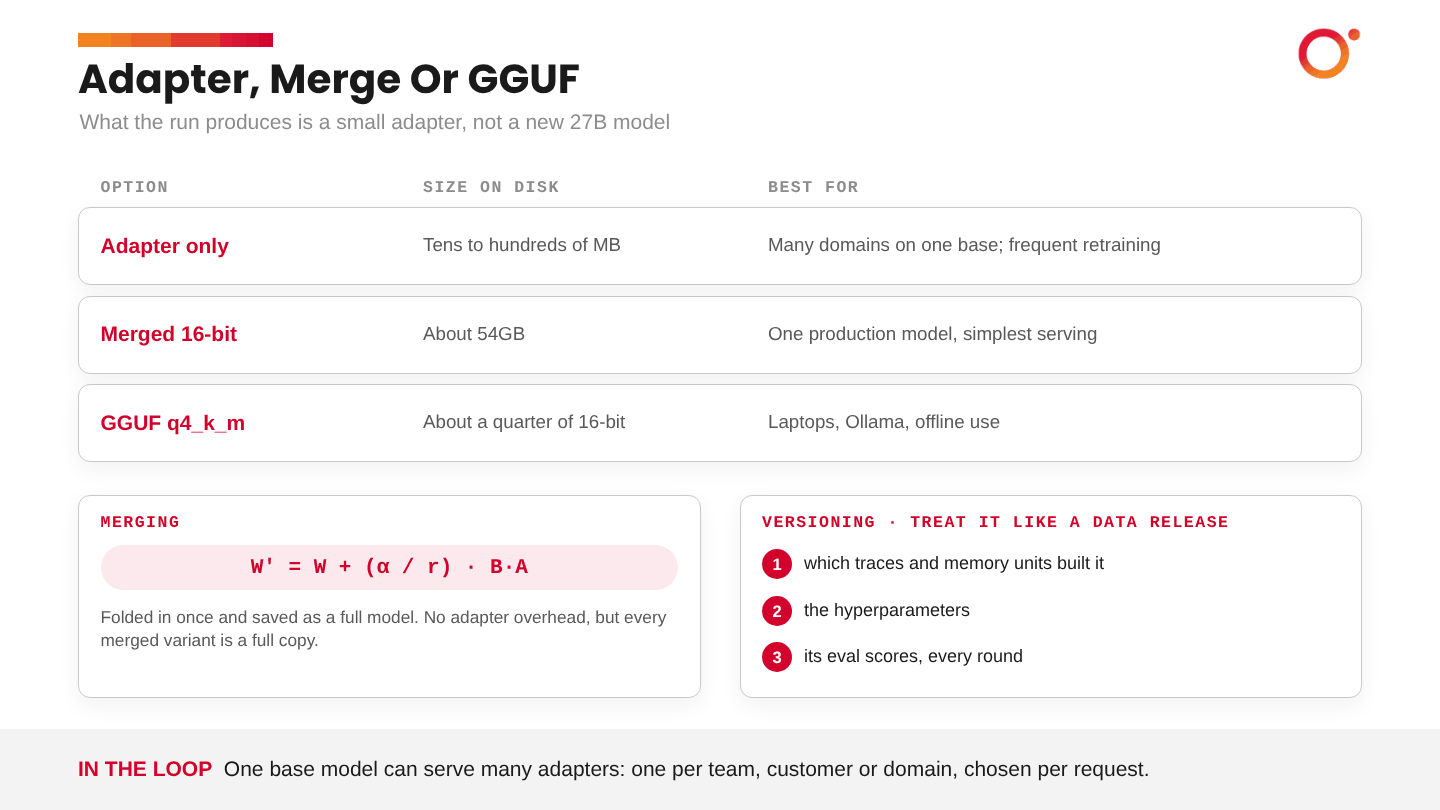

*Figure 26. Three ways to ship the result. One base model can serve many adapters, one per team or domain, chosen per request.*

| Option | Size on disk | Best for |
|---|---|---|
| **Adapter only** | Tens to hundreds of MB | Many domains on one base model; frequent retraining |
| **Merged 16-bit** | About 54GB | One production model and the simplest serving |
| **GGUF, quantised** | About a quarter of 16-bit | Laptops, Ollama, offline use |

**Merging** folds the update into the base weights once, $W' = W + \frac{\alpha}{r} BA$, and saves a full model. Serving is simpler, and every merged variant is a full copy.

## Saving: the calls

| Call | What it does |
|---|---|
| `model.save_pretrained("calderwood_lora")` | Writes the adapter weights and config to a folder. The base model is not copied |
| `tokenizer.save_pretrained("calderwood_lora")` | Saves the tokenizer beside it, so the folder is self-contained |
| `push_to_hub(...)` (commented out) | Uploads the same folder to the Hugging Face Hub with an access token |

To use the adapter later, `FastLanguageModel.from_pretrained("calderwood_lora")` loads the base model and attaches it in one call. The original Unsloth notebook has the cells for merging and for GGUF export.

In [ ]:
model.save_pretrained("calderwood_lora")
tokenizer.save_pretrained("calderwood_lora")
# model.push_to_hub("your_name/calderwood_lora", token = "YOUR_HF_TOKEN")
# tokenizer.push_to_hub("your_name/calderwood_lora", token = "YOUR_HF_TOKEN")

Compare the size of what you just saved with the size of the model it adapts.

In [ ]:
size = sum(os.path.getsize(os.path.join(folder, f)) for folder, _, files in os.walk("calderwood_lora") for f in files)
print(f"Adapter folder: {size / 1e6:,.0f} MB")
print(f"Base model in 16-bit: about {27.4e9 * 2 / 1e6:,.0f} MB")

**Version every adapter like a data release.** Record which traces and memory units it was built from, the hyperparameters, and its evaluation scores. That habit is optional for one run and essential once you train adapter after adapter, which is the subject of the last part.

---
# Part 12: From one run to continual learning

Everything so far was **one round**. Continual learning repeats that round every time new traces arrive, and measures what each round keeps as carefully as what it adds.

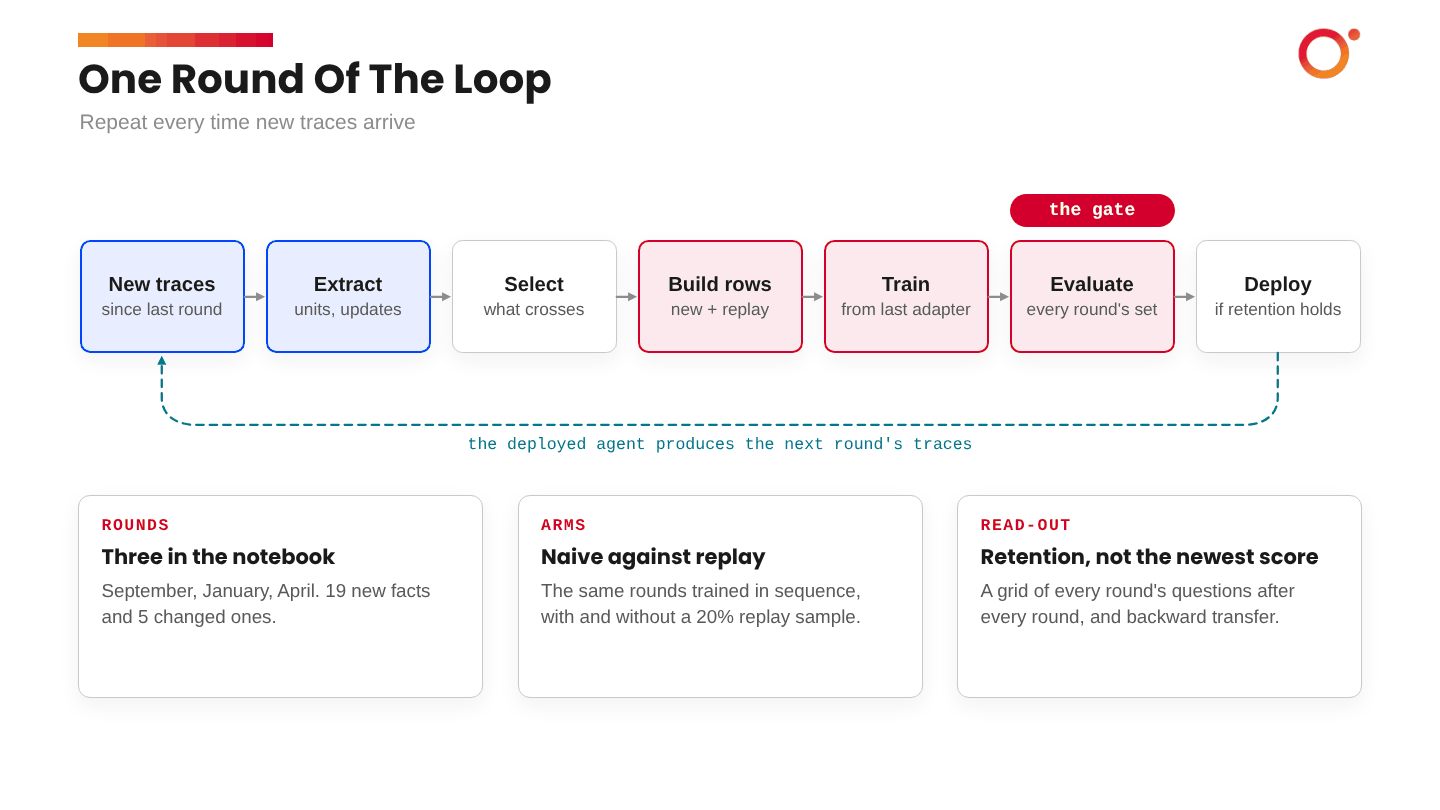

*Figure 27. One round of the loop. The gate is the evaluation: an adapter ships only if retention holds.*

## One round, step by step

1. **New traces** arrive from the agent's work since the last round.
2. **Extraction** produces new memory units and updates existing ones.
3. A **consolidation policy** picks which units go into training this round.
4. **Training rows** are built: the new units, plus a replay sample of earlier rows.
5. The adapter is **trained**, starting from the previous round's adapter.
6. The evaluation re-tests **every round's questions**, not only the newest.
7. If retention holds, the new adapter is **versioned and deployed**.

## When a fact changes: forget, don't delete

Suppose Calderwood retires Drop and customers upload through a new system, Compass. The memory store can keep both versions, with the old unit marked superseded. The weights cannot delete the old value. The new one has to be trained in, ideally with rows that state the change, and the evaluation has to fail any answer that still says Drop.

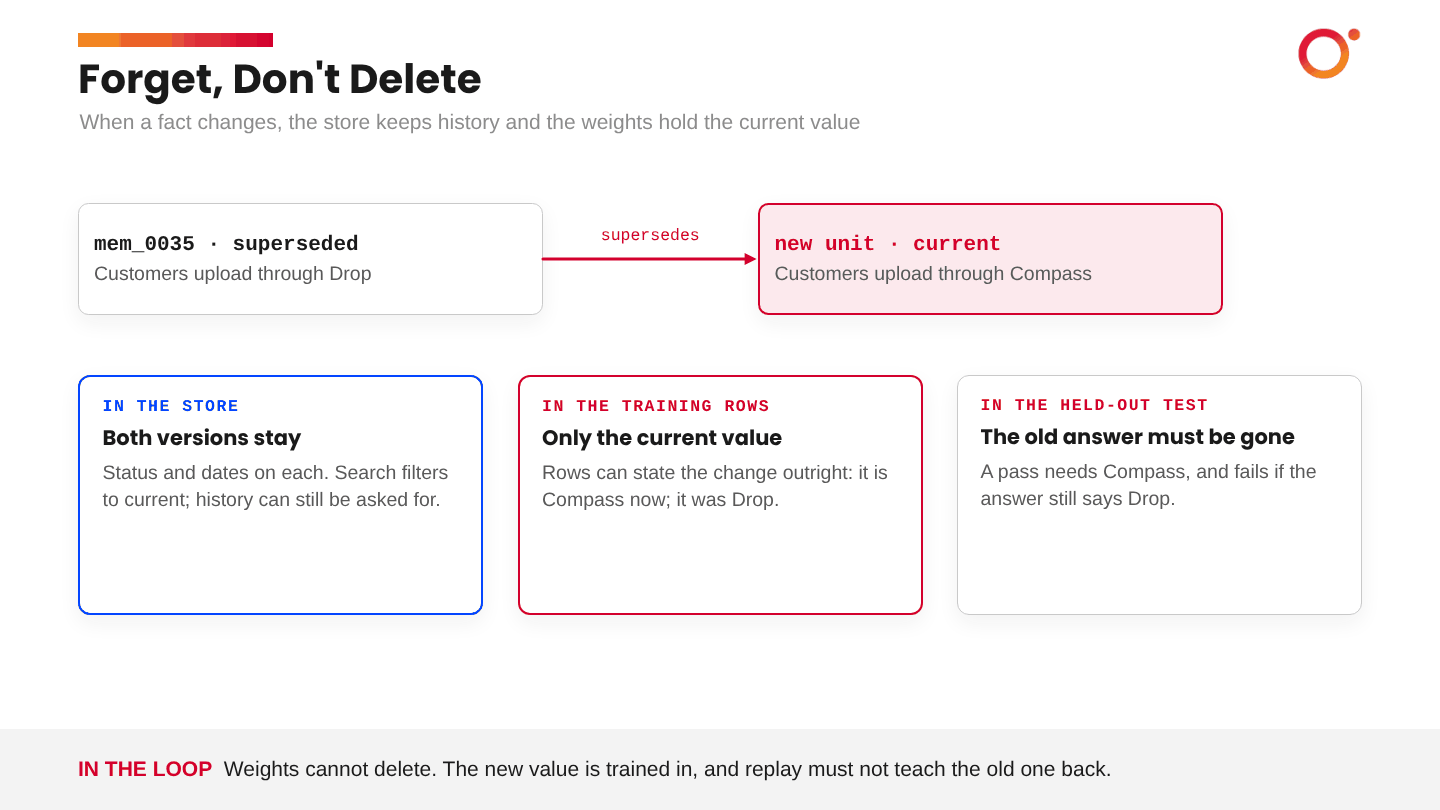

*Figure 28. The store keeps the history. The training rows carry only the current value. The held-out test checks the old answer is gone.*

## Replay

The main defence against forgetting is the one the brain uses. **Replay** mixes a share of earlier rows, often 10 to 20%, into each round, so old knowledge is rehearsed while new knowledge is learned.

One rule matters: the replay pool must be filtered. Replaying a row about Drop after Drop was retired would teach the old value straight back in, so rows tied to superseded facts are taken out.

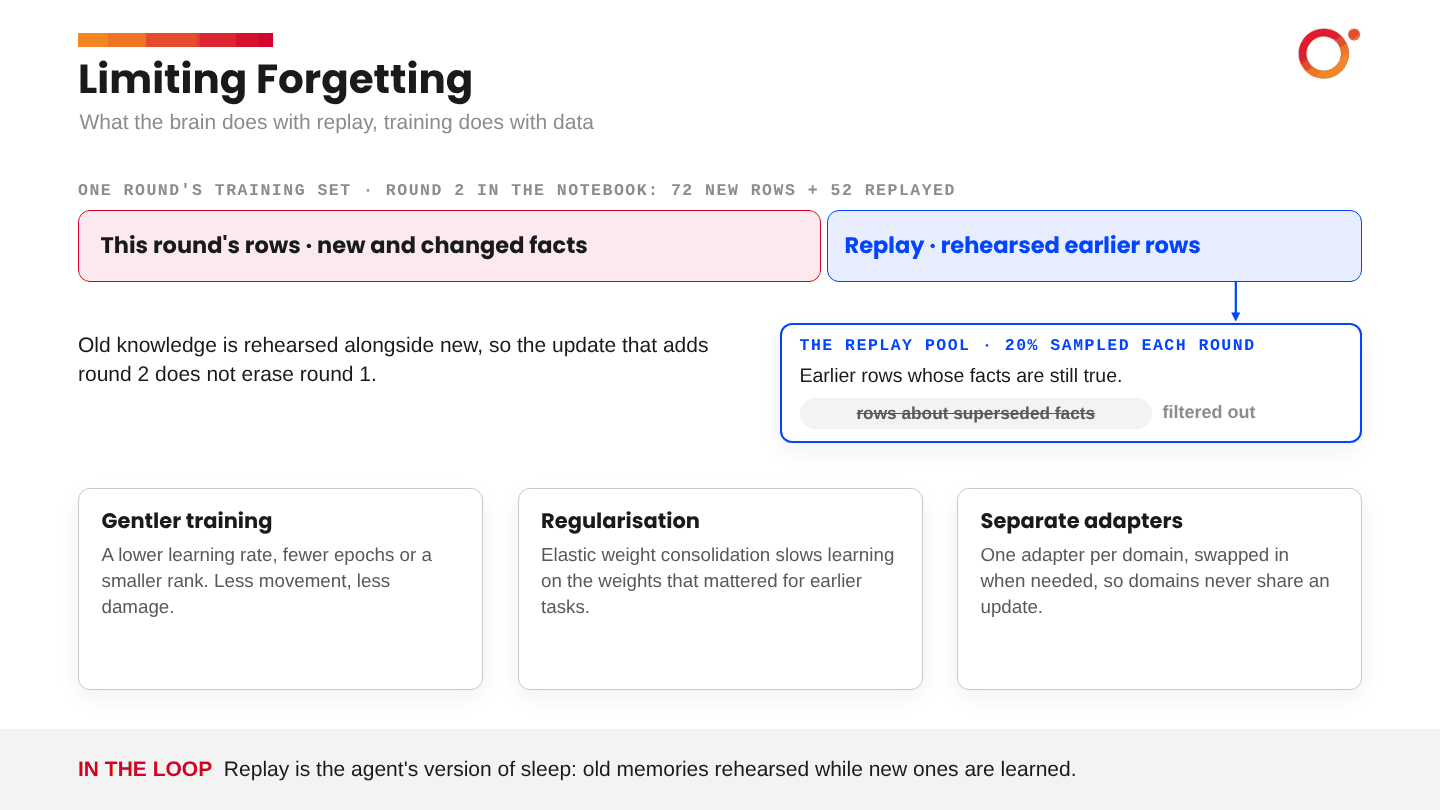

*Figure 29. A round's training set, drawn to scale for round two of the companion notebook: the round's own rows plus a replay sample drawn from 20% of the pool of earlier rows. Three other ways to limit forgetting sit underneath.*

## Measuring retention

After each round, score the eval set of **every round so far**. That produces a grid: rows are "after round k", columns are "round j's questions". Read down a column; if the score falls after later rounds, that is forgetting. Three numbers summarise the grid:

- **Average accuracy:** the mean across all rounds' questions after the latest round.
- **Backward transfer:** how much earlier rounds' scores changed after later training. Negative means forgetting.
- **Forward transfer:** whether earlier rounds made later learning easier.

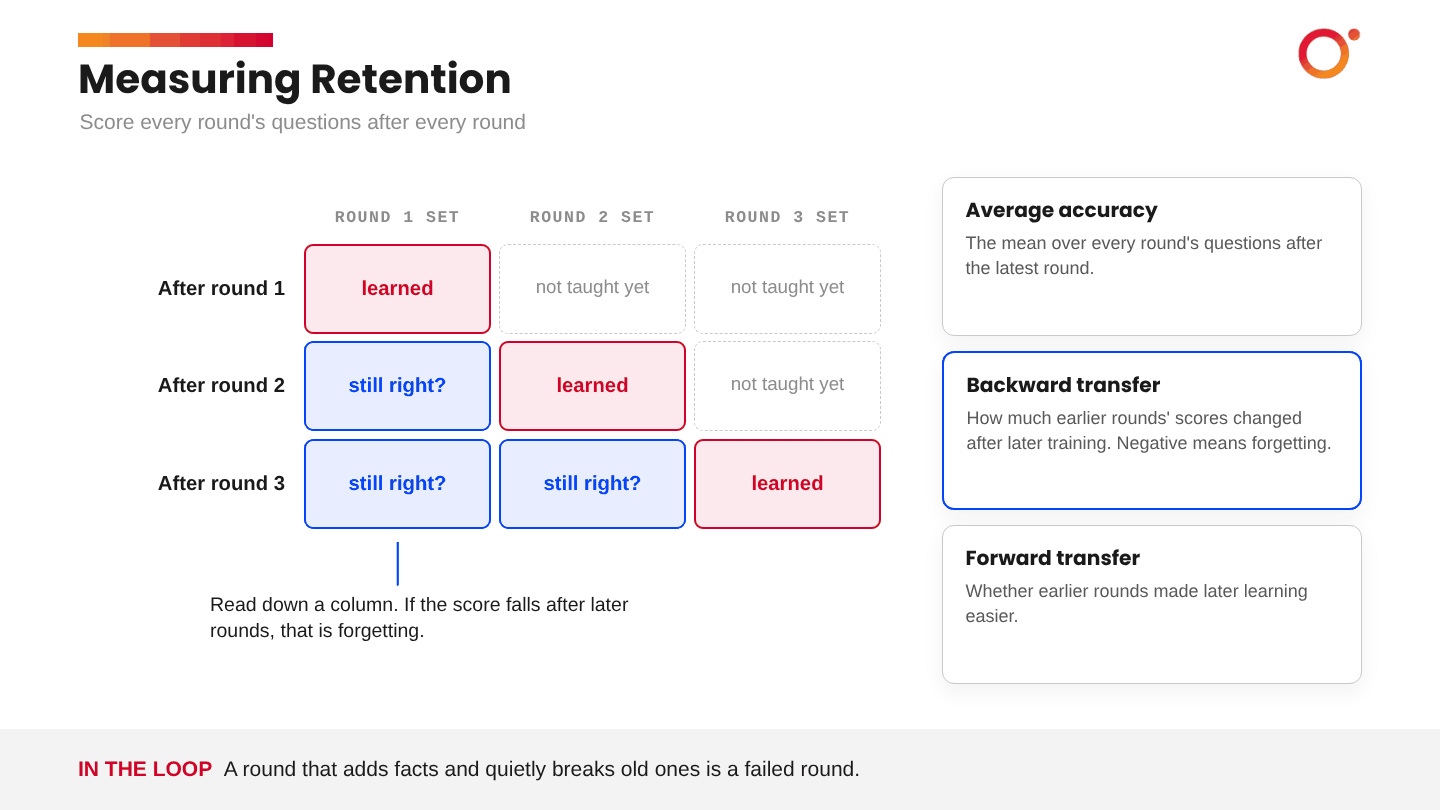

*Figure 30. The retention grid. A round that adds facts and quietly breaks old ones is a failed round.*

## Deciding what to consolidate

Not every memory unit belongs in the weights. Good signals that one does: it is **recalled often** (`recall_count` from Part 4), it has been **stable** for several rounds, and **retrieval misses it**. Deciding what crosses from the store into the model, and when, is where memory engineering and model training meet.

## Where to go next

The companion notebook, `Qwen3_5_27B_Calderwood_continual_learning.ipynb`, runs this loop over three rounds of Calderwood data (September 2026, January 2027, April 2027) with 19 new facts and 5 changed ones. It trains two ways side by side, naive sequential training and the same rounds with a 20% replay sample, and produces the retention grid and the backward-transfer number.

---
# Reference

## Common errors and what they mean

| Symptom | Likely cause | Fix |
|---|---|---|
| "Missing train.jsonl" assertion | Files were dropped into `sample_data` | Drag them onto the root folder, or run `!mv /content/sample_data/*.jsonl /content/` |
| CUDA out of memory while loading | The runtime is a T4 or L4 | Change the runtime to A100, or set `load_in_4bit = True` to run as QLoRA |
| CUDA out of memory during training | Activations from batch size × sequence length | `per_device_train_batch_size = 2` and `gradient_accumulation_steps = 4`: the same effective batch |
| Generation crawls, or a training error mentions checkpointing | A missed `for_inference` or `for_training` switch | Call the matching one in the cell before |
| The masking check prints the question as well as the answer | `instruction_part` or `response_part` do not match the template | Print one row's `text` and copy the exact markers |
| The base model scores above zero on Calderwood categories | Key-term false positives, often an answer that echoes the question | Read those answers; tighten `must_include` |
| Loss near zero within the first epoch | Memorisation | Fewer epochs, or a learning rate of 1e-4; trust the held-out score, not the loss |
| `prior_knowledge` drops after training | Over-learning the collision acronyms | Fewer epochs or a lower learning rate |
| Scores swing between runs | Sampling left on, or a changed system prompt | Keep `do_sample = False` and the same prompt for both passes |

## Glossary

| Term | Meaning |
|---|---|
| Adapter | The small set of trained LoRA weights, saved separately from the base model |
| Alpha | The LoRA scaling factor; the update is multiplied by alpha / r |
| Backward transfer | The change in earlier rounds' scores after later training; negative means forgetting |
| bf16 | A 16-bit floating-point format with fp32's range, standard for training |
| Catastrophic forgetting | Loss of existing ability caused by training on new data |
| Chat template | The format that turns roles and messages into one token string |
| Consolidation | Moving selected knowledge from an external store into the weights |
| Continual learning | Accumulating information and experience repeatedly, over time, keeping what came before |
| Cross-entropy loss | The negative log probability of the correct next token, averaged |
| Effective batch | Batch size × gradient accumulation steps |
| Epoch | One full pass over the training rows |
| Episodic memory | Memory of specific events; stays in the store |
| Gradient checkpointing | Recomputing activations in the backward pass to save memory |
| Greedy decoding | Always choosing the most likely next token |
| Held-out set | Evaluation data kept out of training and out of the traces |
| Knowledge conflict | A new fact that contradicts one from pretraining, such as the colliding acronyms |
| KV cache | Stored keys and values that speed up generation; the model's latent space |
| Leakage | Evaluation content appearing in the training data |
| Learning rate | The size of each weight update; 2e-4 here |
| LoRA | Low-Rank Adaptation: a trained low-rank update beside frozen weights |
| Memory unit | One self-contained piece of knowledge extracted from traces |
| Merge | Folding the adapter into the base weights to make one full model |
| Multi-hop | A question that needs two or more facts combined |
| Procedural memory | Knowing how to do something |
| QLoRA | LoRA on a 4-bit quantised base model |
| Quantisation | Storing weights in fewer bits to save memory, at some cost in accuracy |
| Rank (r) | The capacity of a LoRA adapter: how many directions of change it can learn |
| Replay | Mixing earlier data into later training to limit forgetting |
| Response-only training | Counting the loss only on the assistant's tokens |
| Reversal curse | Learning "A is B" without learning "B is A" |
| Semantic memory | Facts and meanings |
| SFT | Supervised fine-tuning on chosen input and output examples |
| Step | One weight update |
| Target modules | The matrices inside each block that receive a LoRA adapter |
| Token space | Text outside the model that it reads: the store and the context window |
| Trace | The full record of an agent session: messages, tool calls, results |
| Weight space | The model's parameters and any adapters trained on them |
| Zero initialisation | B starts at zero, so a fresh adapter leaves the model unchanged |

## Further reading

- *LoRA: Low-Rank Adaptation of Large Language Models*, Hu et al., 2021. The method in Part 6.
- *QLoRA: Efficient Finetuning of Quantized LLMs*, Dettmers et al., 2023. Training on a 4-bit base.
- *LoRA Learns Less and Forgets Less*, Biderman et al., 2024. The trade-off against full fine-tuning.
- *Transformer Feed-Forward Layers Are Key-Value Memories*, Geva et al., 2021. Where facts may live.
- *Physics of Language Models: Part 3.1, Knowledge Storage and Extraction*, Allen-Zhu and Li, 2023. Why paraphrases matter.
- *The Reversal Curse*, Berglund et al., 2023. Learning "A is B" without "B is A".
- *Fine-Tuning or Retrieval? Comparing Knowledge Injection in LLMs*, Ovadia et al., 2024.
- *Does Fine-Tuning LLMs on New Knowledge Encourage Hallucinations?*, Gekhman et al., 2024.
- *Catastrophic Interference in Connectionist Networks*, McCloskey and Cohen, 1989. The origin of the forgetting problem.
- *Gradient Episodic Memory for Continual Learning*, Lopez-Paz and Ranzato, 2017. Backward and forward transfer.
- *Why There Are Complementary Learning Systems in the Hippocampus and Neocortex*, McClelland, McNaughton and O'Reilly, 1995.
- The Unsloth documentation, and the original Qwen3.5-27B notebook this run is built on.